In [1]:
import numpy as np
import pandas as pd
import os
from urllib.parse import unquote
import random
from time import sleep
import pickle
import json
import copy
import re
import regex
import matplotlib.pyplot as plt
import numpy as np
import ast
import parse
from glob import glob
import yaml
from itertools import cycle
import sys
import seaborn as sns
from transformers import AutoTokenizer
sys.path.append('../')
from utils import effective_path, extract_json_from_response, get_paths_real_sample

#change default font size
plt.rcParams.update({'font.size': 14})



%load_ext autoreload
%autoreload 2

random.seed(42)
pd.set_option('display.max_colwidth', 1000)

PATH_IN = '../../data/wikispeedia/wikispeedia_paths-and-graph/'
LOGS_PATH = '../../logs/inference/'

/dlabdata1/charneca/miniconda3/envs/wikinav/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Analyse Sweep Data

In [2]:
# Load real paths data
paths_real_df = pd.read_csv(os.path.join(PATH_IN, 'paths_real_processed.tsv'), sep='\t', low_memory=False)
shpl_paths_real_df = paths_real_df.query('is_path_finished==1').groupby(['src','tgt']).agg({'hpl':'min', 'path':'first', 'user_path_rating':'first'}).reset_index()
spl_paths_real_df = paths_real_df.query('is_path_finished==1').groupby(['src','tgt']).agg({'spl':'min'}).reset_index()
shepl_paths_real_df = paths_real_df.query('is_path_finished==1').groupby(['src','tgt']).agg({'shepl':'min'}).reset_index()

# Specify the paths to the folders containing the runs
folders = []
folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/simplified_constr_fewshot/2023-11-25_14-55-40/*/"))]
# folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/mistral_finetunes_fewshot/2023-11-13_11-49-05/*/"))]
# folders += [folder for folder in glob(os.path.join(LOGS_PATH, "multiruns/constr_fewshot_ordered_reminder/2023-11-12_13-57-28/*/"))] # llama 7b chat
identifiers = ['model.model_name','agent.fewshot']
all_runs_df = pd.DataFrame() # DataFrame to hold all runs

for folder in folders:
    # Load the configuration for each run
    with open(os.path.join(folder, '.hydra/config.yaml'), 'r') as f:
        config = yaml.safe_load(f)
        config_dict = {}                  
        for identifier in identifiers:
            identifier_keys = identifier.split('.')
            # Extract the identifier value from the config
            config_value = config
            for key in identifier_keys:
                config_value = config_value.get(key)
            config_dict[identifier] = config_value

    config_dict['run_id'] = folder.split('/')[-2]
    print(config_dict)
    # Load the run data
    run_df = pd.read_csv(os.path.join(folder, 'agent_runs.tsv'), sep='\t')

    # add columns
    run_df = run_df.merge(shpl_paths_real_df, on=['src', 'tgt'], how='left')
    run_df = run_df.merge(spl_paths_real_df, on=['src', 'tgt'], how='left')
    run_df = run_df.merge(shepl_paths_real_df, on=['src', 'tgt'], how='left')
    # run_df['error_type'] = run_df['action'].apply(lambda x: "no_error" if "{'next_page'" in x else "PageNotInCands" if "Try a different page" in x else "BackOnFirstPage" if "Cannot go back any further" in x else "BadResponse")
    run_df['path_len'] = run_df['path_so_far'].apply(lambda x: len(x.split(';'))) #should be len-1 but we automatically click on final page
    run_df['effective_path_len'] = run_df['path_so_far'].apply(lambda x: len(effective_path(x).split(';')))
    run_df['diff_from_best_human'] = run_df['path_len'] - run_df['hpl']
    run_df['effective_diff_from_spl'] = run_df['effective_path_len'] - run_df['spl']
    run_df['effective_diff_from_shepl'] = run_df['effective_path_len'] - run_df['shepl']
    run_df['success'] = run_df['is_finished_reason'].apply(lambda x: 1 if x=='success' else 0)

    # Add identifier columns to the run data DataFrame
    for key, value in config_dict.items():
        run_df[key] = value

    # Concatenate this run's DataFrame to the main DataFrame
    all_runs_df = pd.concat([run_df, all_runs_df], ignore_index=True)


{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 0, 'run_id': '0'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 1, 'run_id': '1'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 2, 'run_id': '2'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 3, 'run_id': '3'}
{'model.model_name': 'meta-llama/Llama-2-7b-chat-hf', 'agent.fewshot': 4, 'run_id': '4'}
{'model.model_name': 'ehartford/dolphin-2.2.1-mistral-7b', 'agent.fewshot': 0, 'run_id': '0 copy'}
{'model.model_name': 'ehartford/dolphin-2.2.1-mistral-7b', 'agent.fewshot': 1, 'run_id': '1 copy'}
{'model.model_name': 'ehartford/dolphin-2.2.1-mistral-7b', 'agent.fewshot': 2, 'run_id': '2 copy'}
{'model.model_name': 'ehartford/dolphin-2.2.1-mistral-7b', 'agent.fewshot': 3, 'run_id': '3 copy'}
{'model.model_name': 'ehartford/dolphin-2.2.1-mistral-7b', 'agent.fewshot': 4, 'run_id': '4 copy'}
{'model.model_name': 'Open-Orca/Mistral-7B-OpenOrca', 'agent

In [20]:
all_runs_df.columns

Index(['agent_id', 'agent_type', 'cur', 'src', 'tgt', 'response', 'action',
       'num_actions', 'num_tries', 'num_errors', 'is_finished',
       'is_finished_reason', 'path_so_far', 'user_prompt', 'hpl', 'path',
       'user_path_rating', 'spl', 'shepl', 'path_len', 'effective_path_len',
       'diff_from_best_human', 'effective_diff_from_spl',
       'effective_diff_from_shepl', 'success', 'model.model_name',
       'agent.fewshot', 'run_id'],
      dtype='object')

In [22]:
all_runs_df[all_runs_df['model.model_name']=='teknium/OpenHermes-2.5-Mistral-7B'][all_runs_df['agent.fewshot']==1][all_runs_df['agent_id'] <= 9].query('is_finished==True')[['src','tgt','is_finished_reason', 'path_len', 'num_errors']]

/tmp/ipykernel_3518225/1634943494.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  all_runs_df[all_runs_df['model.model_name']=='teknium/OpenHermes-2.5-Mistral-7B'][all_runs_df['agent.fewshot']==1][all_runs_df['agent_id'] <= 9].query('is_finished==True')[['src','tgt','is_finished_reason', 'path_len', 'num_errors']]
/tmp/ipykernel_3518225/1634943494.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  all_runs_df[all_runs_df['model.model_name']=='teknium/OpenHermes-2.5-Mistral-7B'][all_runs_df['agent.fewshot']==1][all_runs_df['agent_id'] <= 9].query('is_finished==True')[['src','tgt','is_finished_reason', 'path_len', 'num_errors']]


,src,tgt,is_finished_reason,path_len,num_errors
26463,History_of_democracy,Romania,success,2,0
26584,Special_relativity,Sound,success,3,0
26644,Diabetes_mellitus,Adolf_Hitler,success,3,0
26691,Saltasaurus,Battle_of_Stalingrad,success,4,0
26763,Apple,Adolf_Hitler,success,4,0
26764,Cheers,Tashkent,success,6,0
26825,Cleopatra_VII,Ottawa,success,7,0
26870,Ukraine,Great_Barrier_Reef,success,9,0
26993,Calgary,Zebra,success,10,0
27008,Flamingo,Gold(III)_chloride,success,16,0


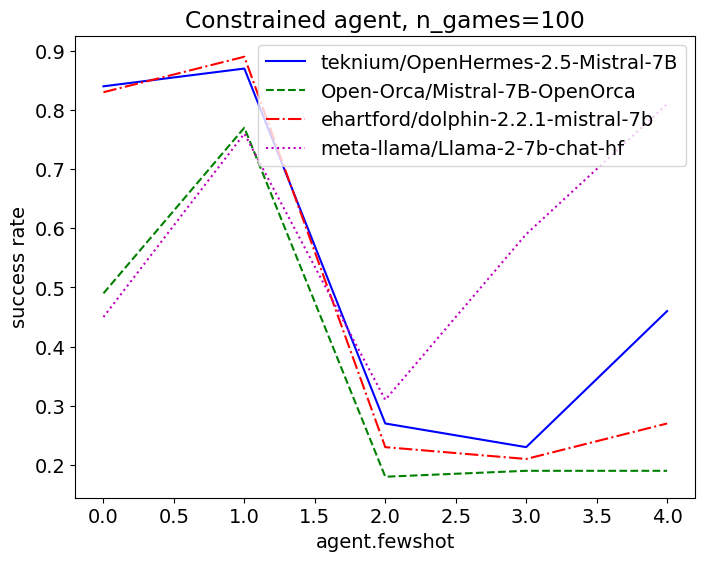

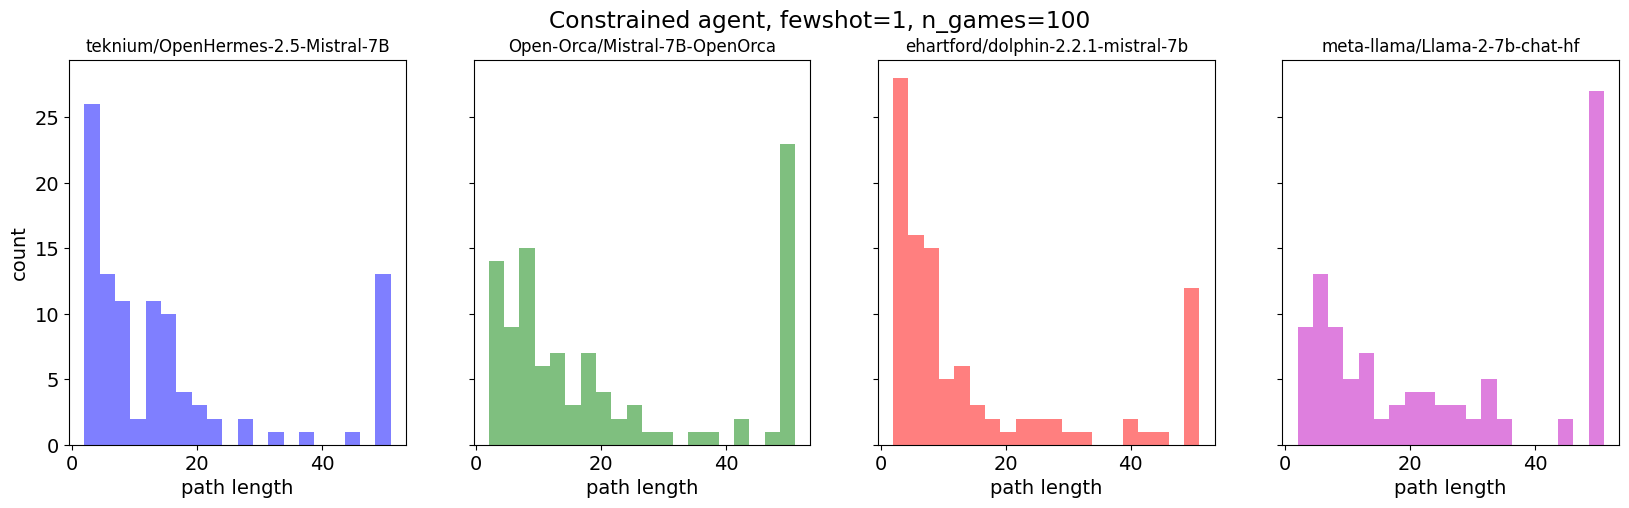

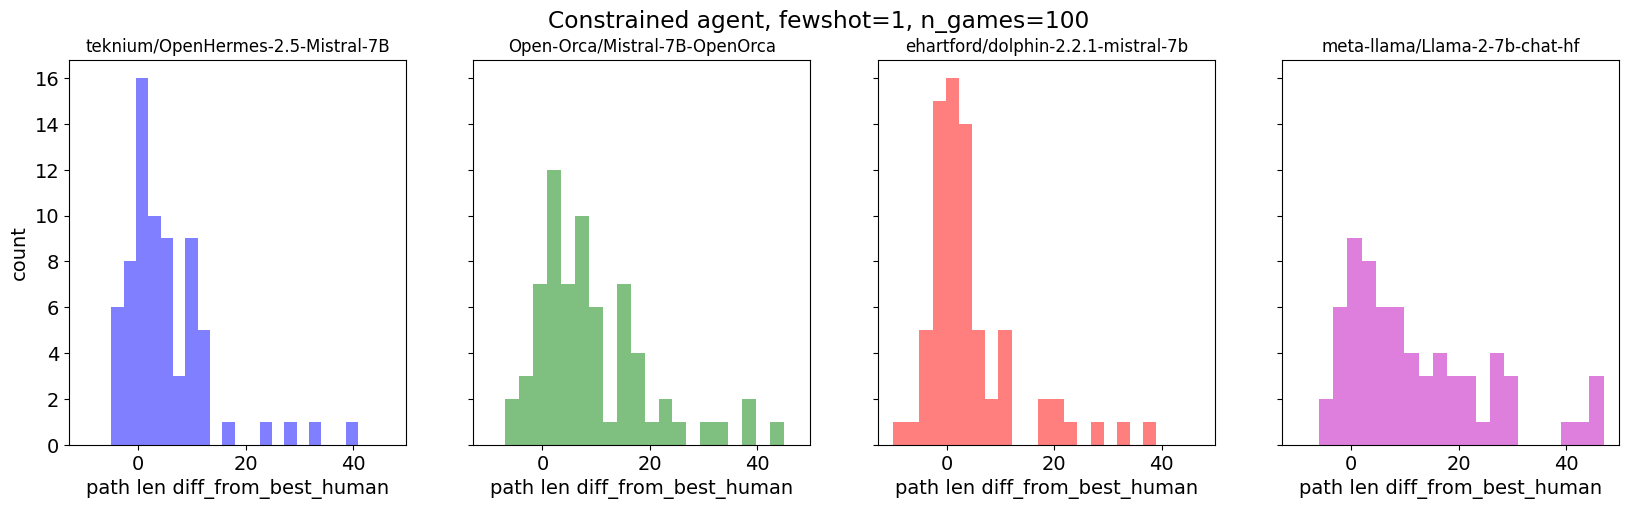

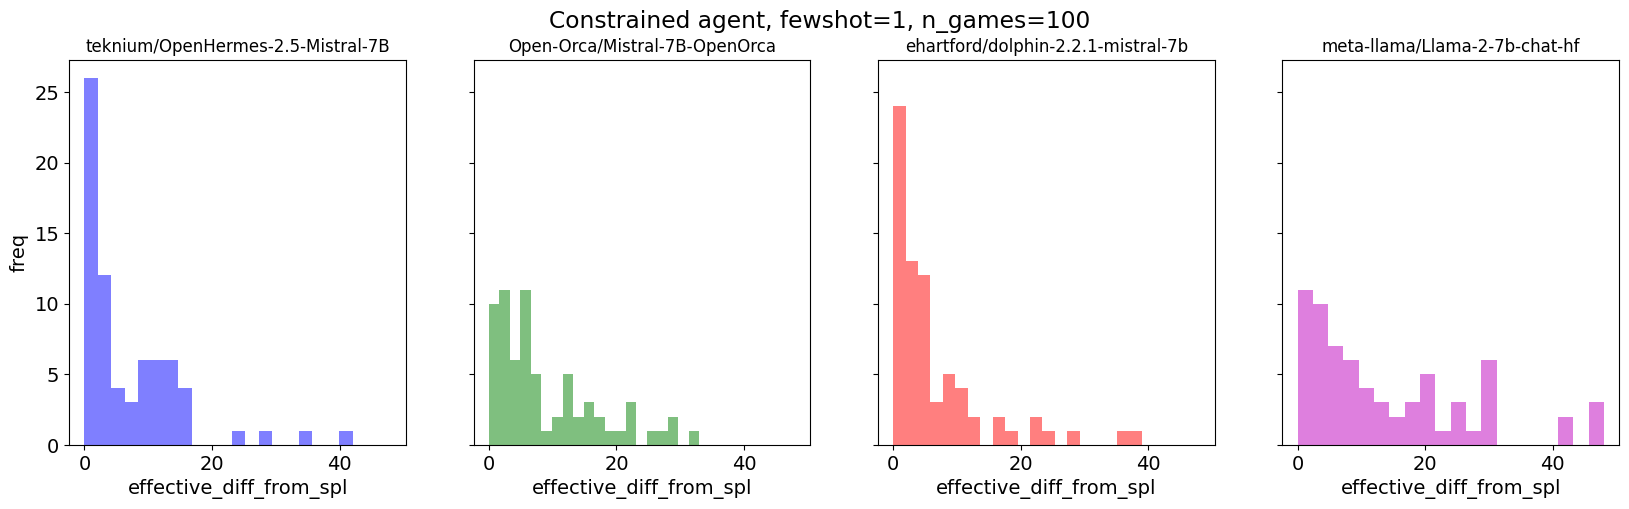

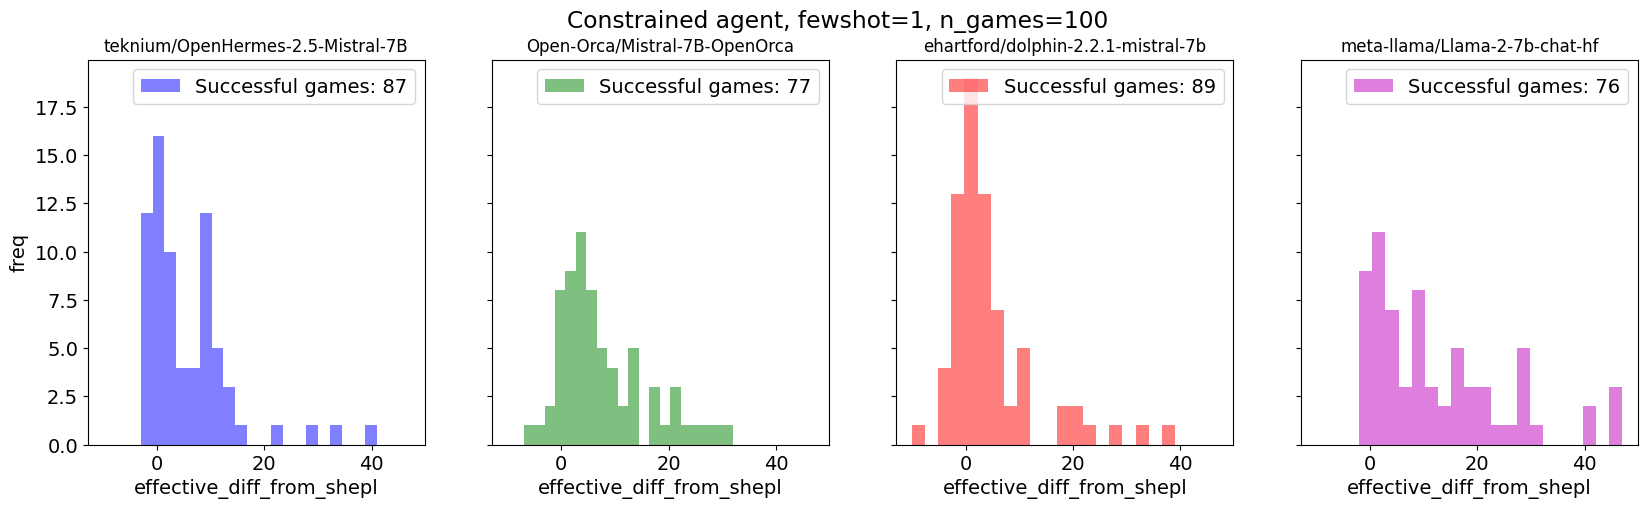

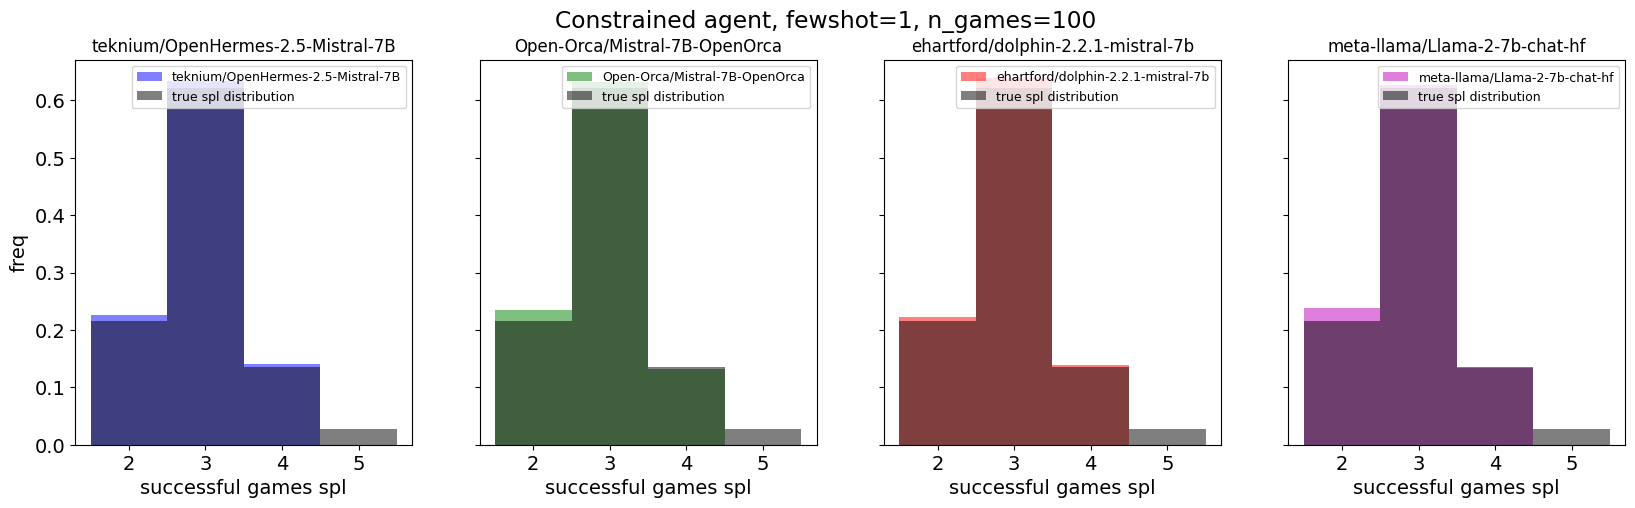

In [15]:
# all_runs_df has the columns: 'agent_id', 'agent_type', 'cur', 'src', 'tgt', 'response', 'action','num_actions', 'num_tries', 'num_errors', 'is_finished','is_finished_reason', 'path_so_far', 'user_prompt', 'hpl', 'path','user_path_rating', 'spl', 'path_len', 'effective_path_len','diff_from_best_human', 'diff_from_spl', 'success', 'model.model_name','agent.fewshot', 'run_id'

# for finished runs (is_finished == True), make a line plot: y=success rate, x=agent.fewshot, plot a line for each
lines = ["-","--","-.",":", "-","--","-.",":"]
colors = ['b', 'g', 'r', 'm', 'y', 'k', 'c']
bins = 20

plt.figure(figsize=(8,6))
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    df = all_runs_df[all_runs_df[identifiers[0]] == identifier].query('is_finished == True')
    df = df.groupby(identifiers[1]).agg({'success':'mean'}).reset_index()
    plt.plot(df[f'{identifiers[1]}'], df['success'], label=identifier, linestyle=lines[i], color=colors[i])
plt.legend(); plt.title('Constrained agent, n_games=100'); plt.xlabel(f'{identifiers[1]}'); plt.ylabel('success rate'); plt.show()

# plot histogram of final path lengths for each
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==1)].query('is_finished == True')
    axes[i].hist(df['path_len'], label=identifier, bins=bins, alpha=0.5, density=False, color=colors[i])
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('path length')
    if i == 0:
        axes[i].set_ylabel('count')
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# plot histogram of diff_from_best_human for each
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==1)].query('success==1')
    axes[i].hist(df['diff_from_best_human'], label=identifier, bins=bins, alpha=0.5, density=False, color=colors[i])
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('path len diff_from_best_human')
    if i == 0:
        axes[i].set_ylabel('count')
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# plot histogram of diff_from_spl for each
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==1)].query('success==1')
    axes[i].hist(df['effective_diff_from_spl'], label=identifier, bins=bins, alpha=0.5, density=False, color=colors[i])
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('effective_diff_from_spl')
    if i == 0:
        axes[i].set_ylabel('freq')
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()

# plot histogram of diff_from_shepl for each
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==1)].query('success==1')
    axes[i].hist(df['effective_diff_from_shepl'], bins=bins, alpha=0.5, density=False, color=colors[i], label=f"Successful games: {len(df)}")
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('effective_diff_from_shepl')
    axes[i].legend()
    if i == 0:
        axes[i].set_ylabel('freq')
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()


# plot histogram of spl of successful paths for each
fig, axes = plt.subplots(1, len(all_runs_df[identifiers[0]].unique()), figsize=(5*len(all_runs_df[identifiers[0]].unique()),5), sharey=True, sharex=True)
for i,identifier in enumerate(all_runs_df[identifiers[0]].unique()):
    df = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==1)].query('success==1')
    df_all = all_runs_df[(all_runs_df[identifiers[0]] == identifier) & (all_runs_df['agent.fewshot']==1)].query('is_finished==True')
    bins_ = np.arange(df_all['spl'].min(), df_all['spl'].max()+1.5) - 0.5
    axes[i].hist(df['spl'], label=identifier, alpha=0.5, density=True, color=colors[i], bins=bins_)
    #plot the true spl distribution aka for all games
    axes[i].hist(df_all['spl'], label="true spl distribution", alpha=0.5, density=True, color='black', bins=bins_)
    axes[i].set_title(identifier, fontsize=12); axes[i].set_xlabel('successful games spl')
    if i == 0:
        axes[i].set_ylabel('freq')
    axes[i].legend(fontsize=9)
plt.suptitle('Constrained agent, fewshot=1, n_games=100')
plt.show()





# for finished runs (is_finished == True), and for each: y=success rate, x=agent.fewshot, plot a line for each model.model_name


<Axes: >

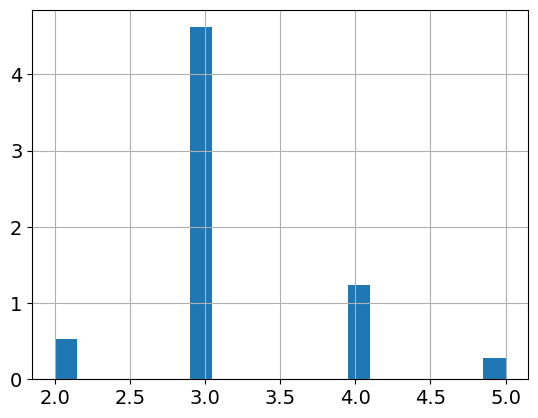

In [13]:
all_runs_df[all_runs_df['model.model_name']=='mistralai/Mistral-7B-Instruct-v0.1']['spl'].hist(bins=20, density=True)
# .query("`agent.fewshot`==1 and success == 1").sort_values(by='effective_diff_from_spl', ascending=True).head(10)

In [3]:
# Error types:
# - "Try a different page" = PageNotInCands
# - "Cannot go back any further" = BackOnFirstPage
# - else = BadResponse
for run in runs:
    print("\nRun config:")
    for key in run.keys():
        if key != 'df':
            print(f"\t{key} = {run[key]}")
    run_df = run['df']
    # add columns
    run_df = run_df.merge(shpl_paths_real_df, on=['src', 'tgt'], how='left')
    run_df['error_type'] = run_df['action'].apply(lambda x:
                                                "no_error" if "{'next_page'" in x else
                                                "PageNotInCands" if "Try a different page" in x else
                                                "BackOnFirstPage" if "Cannot go back any further" in x else
                                                "BadResponse")
    run_df['path_len'] = run_df['path_so_far'].apply(lambda x: len(x.split(';'))) #should be -1 but we automatically click on final page
    run_df['effective_path_len'] = run_df['path_so_far'].apply(lambda x: len(effective_path(x).split(';')))
    run_df['diff_from_best_human'] = run_df['path_len'] - run_df['hpl']
    run_df['success'] = run_df['is_finished_reason'].apply(lambda x: 1 if x=='success' else 0)

    num_runs = len(run_df.query('is_finished==True')) + 1e-10
    num_errors = run_df.query('is_finished==True')['num_errors'].sum() + 1e-10
    num_actions = run_df.query('is_finished==True')['num_actions'].sum()

    run['df'] = run_df
    
    print("Total number of runs:", int(num_runs))
    print("% of successful runs:", round(len(run_df.query('is_finished_reason=="success"'))/num_runs*100, 1))
    print("Number of back clicks:", run_df.apply(lambda x: x['action'] == "{'next_page': 'NA'}", axis=1).sum())

    print("Statistics on path length (successful runs):")
    print("\tMean:", round(run_df.query('is_finished==True and is_finished_reason=="success"')['path_len'].mean(), 1))
    print("\tMedian:", round(run_df.query('is_finished==True and is_finished_reason=="success"')['path_len'].median(), 1))
    print("\tMin:", run_df.query('is_finished==True and is_finished_reason=="success"')['path_len'].min())
    print("\tMax:", run_df.query('is_finished==True and is_finished_reason=="success"')['path_len'].max())

    print("Statistics on effective path length (successful runs):")
    print("\tMean:", round(run_df.query('is_finished==True and is_finished_reason=="success"')['effective_path_len'].mean(), 1))
    print("\tMedian:", round(run_df.query('is_finished==True and is_finished_reason=="success"')['effective_path_len'].median(), 1))
    print("\tMin:", run_df.query('is_finished==True and is_finished_reason=="success"')['effective_path_len'].min())
    print("\tMax:", run_df.query('is_finished==True and is_finished_reason=="success"')['effective_path_len'].max())

    print("Statistics on difference from best human path (successful runs AND there's a human finished path):")
    print("\tMean:", round(run_df.query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')['diff_from_best_human'].mean(), 1))
    print("\tMedian:", round(run_df.query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')['diff_from_best_human'].median(), 1))
    print("\tMin:", run_df.query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')['diff_from_best_human'].min())
    print("\tMax:", run_df.query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')['diff_from_best_human'].max())


    print("% of failed runs because of max_tries (too many errors):", round(len(run_df.query('is_finished_reason=="max_tries"'))/num_runs*100, 1))
    print("% of failed runs because of max_actions (too many actions):", round(len(run_df.query('is_finished_reason=="max_actions"'))/num_runs*100, 1))
    print("% of error actions:", round(run_df.query('is_finished==True')['num_errors'].sum()/run_df.query('is_finished==True')['num_actions'].sum()*100, 1))
    print("\tFrom which:")
    print("\t% of PageNotInCands:", round(len(run_df.query('error_type=="PageNotInCands"'))/num_errors*100, 1))
    print("\t% of BackOnFirstPage:", round(len(run_df.query('error_type=="BackOnFirstPage"'))/num_errors*100, 1))
    print("\t% of BadResponse:", round(len(run_df.query('error_type=="BadResponse"'))/num_errors*100, 1))
    


Run config:
	model.temperature = 0.1
	run_id = 1
Total number of runs: 100
% of successful runs: 53.0
Number of back clicks: 0
Statistics on path length (successful runs):
	Mean: 12.2
	Median: 10.0
	Min: 2
	Max: 39
Statistics on effective path length (successful runs):
	Mean: 12.2
	Median: 10.0
	Min: 2
	Max: 39
Statistics on difference from best human path (successful runs AND there's a human finished path):
	Mean: 7.1
	Median: 4.5
	Min: -6.0
	Max: 27.0
% of failed runs because of max_tries (too many errors): 7.0
% of failed runs because of max_actions (too many actions): 40.0
% of error actions: 29.1
	From which:
	% of PageNotInCands: 99.6
	% of BackOnFirstPage: 0.0
	% of BadResponse: 0.4

Run config:
	model.temperature = 0.25
	run_id = 6
Total number of runs: 100
% of successful runs: 50.0
Number of back clicks: 0
Statistics on path length (successful runs):
	Mean: 13.7
	Median: 9.5
	Min: 2
	Max: 39
Statistics on effective path length (successful runs):
	Mean: 13.7
	Median: 9.5
	Min

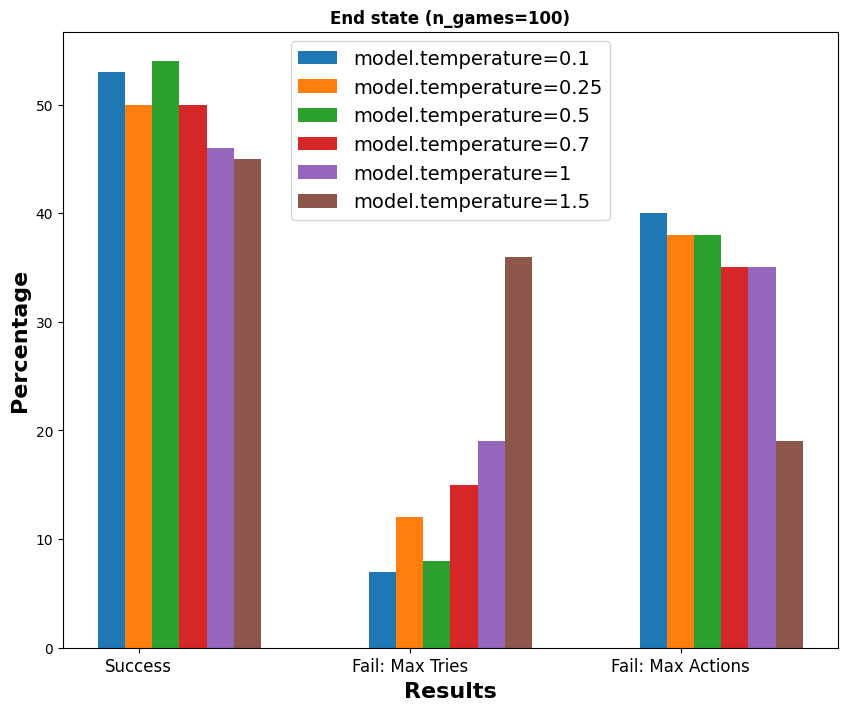

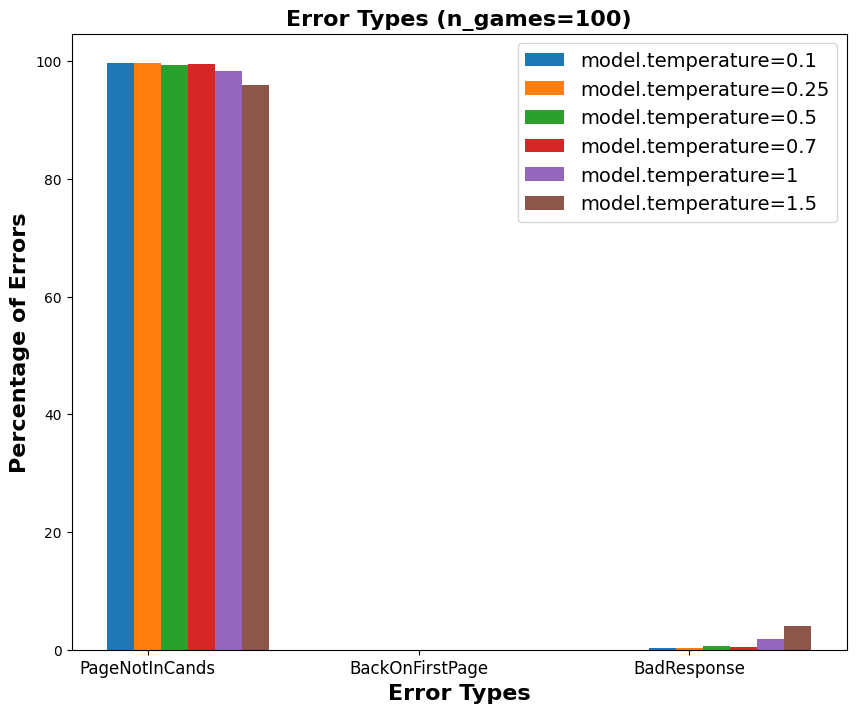

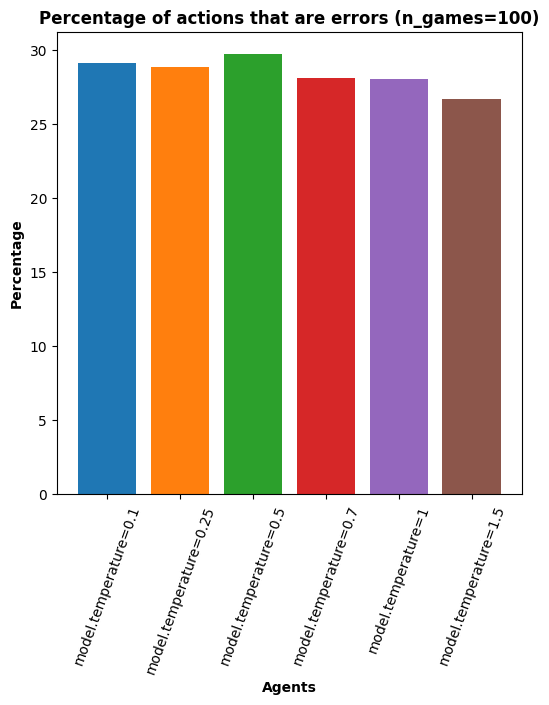

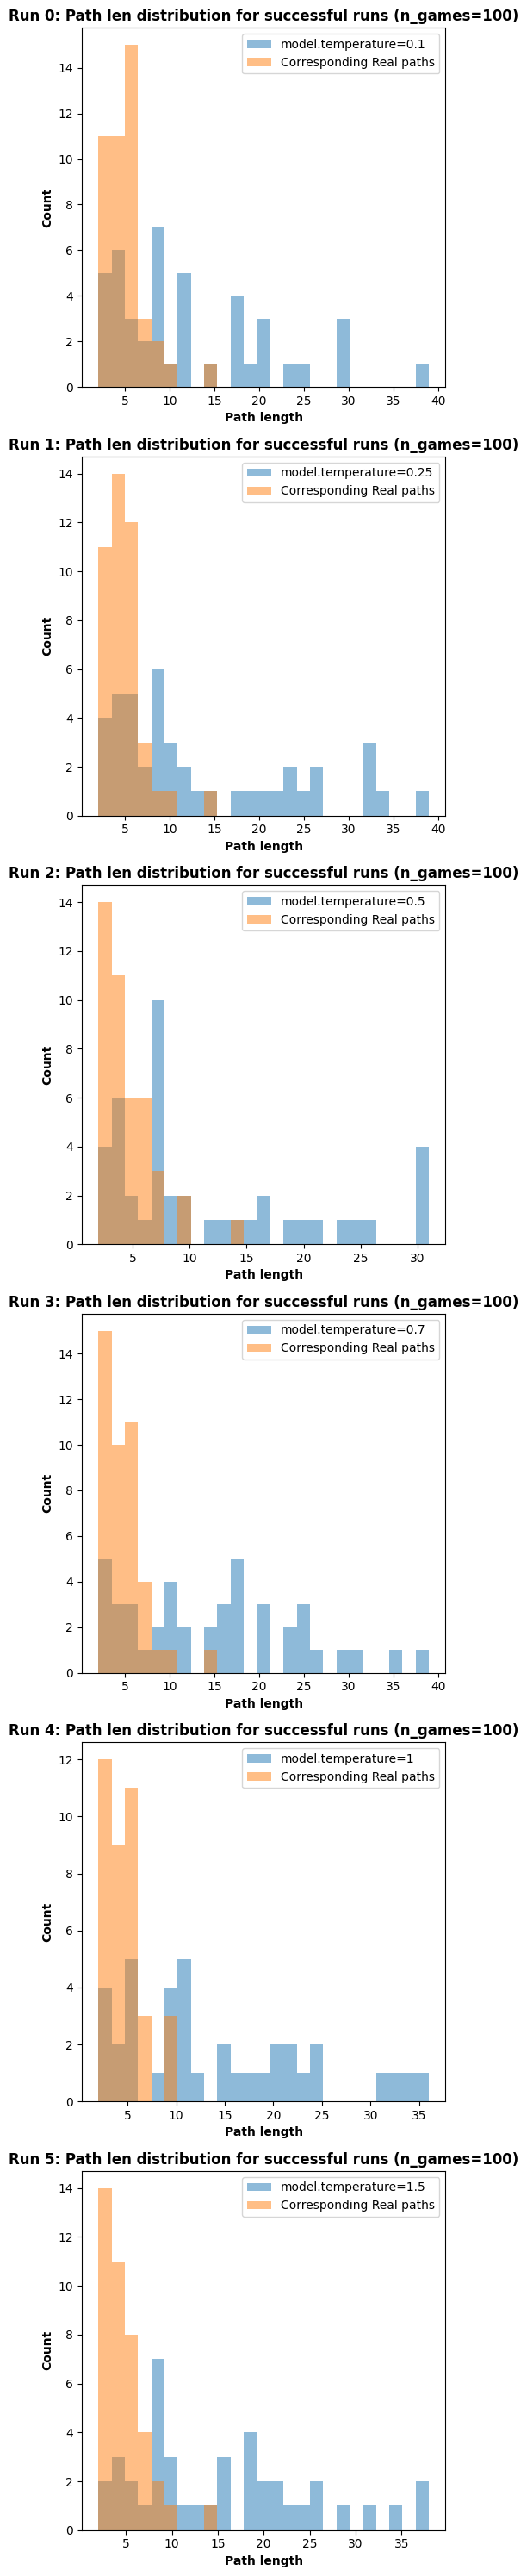

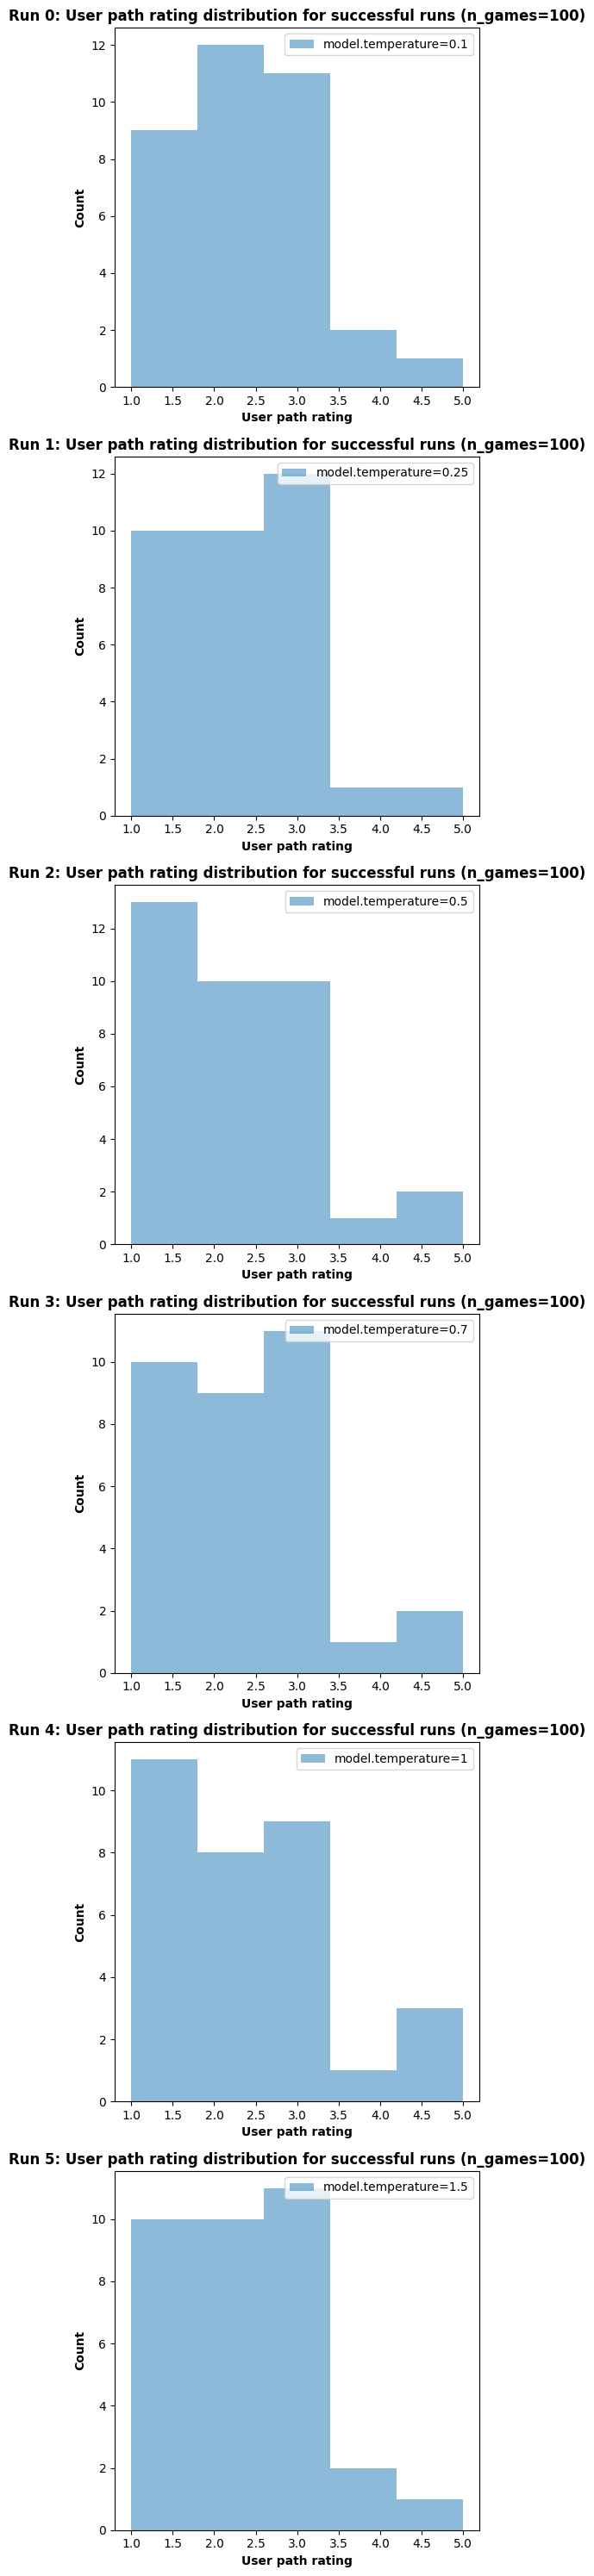

In [14]:
## For experiments with 1 identifier ##

import matplotlib.pyplot as plt
import numpy as np

# Number of runs
n_runs = len(runs)

# Lists for accumulating results and error types
successful_runs = []
max_tries_runs = []
max_actions_runs = []
num_errors_runs = []
percentage_of_back_clicks = []
successful_path_length={"vals":[], "stds":[]}

page_not_in_cands_errors = []
back_on_first_page_errors = []
bad_response_errors = []

for run in runs:
    run_df = run['df']
    num_runs = len(run_df.query('is_finished==True'))
    num_actions = run_df.query('is_finished==True')['num_actions'].sum()
    num_errors = run_df.query('is_finished==True')['num_errors'].sum()

    # Accumulate data for each run
    successful_runs.append(len(run_df.query('is_finished_reason=="success"'))/num_runs*100)
    max_tries_runs.append(len(run_df.query('is_finished_reason=="max_tries"'))/num_runs*100)
    max_actions_runs.append(len(run_df.query('is_finished_reason=="max_actions"'))/num_runs*100)
    percentage_of_back_clicks.append(run_df.apply(lambda x: x['action'] == "{'next_page': 'NA'}", axis=1).sum()/num_actions*100)
    successful_path_length["vals"].append(run_df.query('is_finished_reason=="success"')['path_len'].median())
    successful_path_length["stds"].append(run_df.query('is_finished_reason=="success"')['path_len'].std())
    
    num_errors_runs.append(num_errors/num_actions*100)
    page_not_in_cands_errors.append(len(run_df.query('error_type=="PageNotInCands"'))/num_errors*100)
    back_on_first_page_errors.append(len(run_df.query('error_type=="BackOnFirstPage"'))/num_errors*100)
    bad_response_errors.append(len(run_df.query('error_type=="BadResponse"'))/num_errors*100)

# run_name_to_label = {"constr_fewshot_exper": "Fixed demos sorted by performance", "constr_temp_fewshot": "Fixed demos in original order", "constr_fewshot_random_demos": "Random demos"}
# run_name_to_line_style = {"constr_fewshot_exper": "-", "constr_temp_fewshot": "--", "constr_fewshot_random_demos": "-."}
# # Line plot of identifier vs success rate
# plt.figure(figsize=(6,6))
# for run_name in ['constr_fewshot_exper', 'constr_temp_fewshot', 'constr_fewshot_random_demos']:
#     runs_subset = [run for run in runs if run['run_name']==run_name]
#     successful_runs_subset = [successful_runs[i] for i in range(len(runs)) if runs[i]['run_name']==run_name]
#     plt.plot([run['agent.fewshot'] for run in runs_subset], successful_runs_subset, label=run_name_to_label[run_name], linestyle=run_name_to_line_style[run_name])
# plt.grid(axis='y', alpha=0.75)
# plt.xlabel('agent.fewshot', fontweight='bold')
# plt.ylabel('Success rate', fontweight='bold')
# plt.legend()
# #choose high dpi to make the plot clearer
# plt.savefig('success_rate.png', dpi=300)
# plt.show()

# # plot of identifier vs number of back clicks
# plt.figure(figsize=(6,6))
# plt.plot([run[identifier] for run in runs], percentage_of_back_clicks)
# plt.xlabel(identifier, fontweight='bold')
# plt.ylabel('Percentage of back clicks', fontweight='bold')
# plt.legend()
# plt.show()


# # plot path length for successful runs vs identifier, where the values are the mean and the error bars are the std
# plt.figure(figsize=(6,6))
# plt.errorbar([run[identifier] for run in runs], successful_path_length["vals"], yerr=successful_path_length["stds"], fmt='o')
# plt.xlabel(identifier, fontweight='bold')
# plt.ylabel('Median Path length', fontweight='bold')

# plt.legend()
# plt.show()

bar_width = 0.1
r = np.arange(3)  # For three categories: 'success', 'max_tries', 'max_actions'
r_errors = np.arange(3)  # For three error types

# Plot for run results
plt.figure(figsize=(10,8))
for i in range(n_runs):
    offsets = [j+(bar_width*i) for j in r]
    plt.bar(offsets, [successful_runs[i], max_tries_runs[i], max_actions_runs[i]], width=bar_width, label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Results', fontweight='bold', fontsize=16)
plt.ylabel('Percentage', fontweight='bold', fontsize=16)
plt.xticks([r + bar_width for r in range(3)], ['Success', 'Fail: Max Tries', 'Fail: Max Actions'], fontsize=12)
# plt.xticks([r + bar_width for r in range(3)], ['Success'])
plt.title('End state (n_games=100)', fontweight='bold')
plt.legend(fontsize=14)
plt.show()

# Plot for error types
plt.figure(figsize=(10,8))
for i in range(n_runs):
    offsets = [j+(bar_width*i) for j in r_errors]
    plt.bar(offsets, [page_not_in_cands_errors[i], back_on_first_page_errors[i], bad_response_errors[i]], width=bar_width, label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Error Types', fontweight='bold', fontsize=16)
plt.ylabel('Percentage of Errors', fontweight='bold', fontsize=16)
# use a logy scale
plt.xticks([r + bar_width for r in range(3)], ['PageNotInCands', 'BackOnFirstPage', 'BadResponse'], fontsize=12)
plt.title('Error Types (n_games=100)', fontweight='bold', fontsize=16)
plt.legend(fontsize=14)
plt.savefig('error_types.png', dpi=300)
plt.show()

# Plot for number of errors
plt.figure(figsize=(6,6))
for i in range(n_runs):
    plt.bar(i, num_errors_runs[i], label=f"{identifier}={runs[i][identifier]}")

plt.xlabel('Agents', fontweight='bold')
plt.ylabel('Percentage', fontweight='bold')
plt.xticks([r for r in range(n_runs)], [f"{identifier}={runs[i][identifier]}" for i in range(n_runs)], rotation=70)
plt.title('Percentage of actions that are errors (n_games=100)', fontweight='bold')

# Plot path_len distribution for run 0 and 1 and real_paths for successful runs
n_runs = len(runs)
fig, axes = plt.subplots(n_runs, 1, figsize=(5, 5 * n_runs))  # Creates a column of subplots, one for each run
for i in range(n_runs):
    query_result = runs[i]['df'].query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')
    
    _, bins, _ = axes[i].hist(query_result['path_len'], bins=25, alpha=0.5, label=f"{identifier}={runs[i][identifier]}")
    axes[i].hist(query_result['hpl'].astype(int), bins=bins, alpha=0.5, label=f"Corresponding Real paths")
    
    axes[i].set_xlabel('Path length', fontweight='bold')
    axes[i].set_ylabel('Count', fontweight='bold')
    axes[i].set_title(f'Run {i}: Path len distribution for successful runs (n_games=100)', fontweight='bold')
    axes[i].legend()
plt.tight_layout()
plt.show()

# Plot distribution of user_path_rating for successful runs
n_runs = len(runs)
fig, axes = plt.subplots(n_runs, 1, figsize=(5, 5 * n_runs))  
for i in range(n_runs):
    query_result = runs[i]['df'].query('is_finished==True and is_finished_reason=="success" and hpl.notnull()')
    
    axes[i].hist(query_result['user_path_rating'], bins=5, alpha=0.5, label=f"{identifier}={runs[i][identifier]}")
    
    axes[i].set_xlabel('User path rating', fontweight='bold')
    axes[i].set_ylabel('Count', fontweight='bold')
    axes[i].set_title(f'Run {i}: User path rating distribution for successful runs (n_games=100)', fontweight='bold')
    axes[i].legend()
plt.tight_layout()
plt.show()




In [3]:
## For experiments with 2 identifiers ##
# Assuming you have lists of unique fewshot values and temperature values
fewshot_values = sorted(set(run['agent.fewshot'] for run in runs))
temperature_values = sorted(set(run['model.temperature'] for run in runs))

# Initialize your matrices
success_rate_matrix = {"val":np.zeros((len(fewshot_values), len(temperature_values))), "error":np.zeros((len(fewshot_values), len(temperature_values)))}
mean_path_len_matrix = {"val":np.zeros_like(success_rate_matrix['val']), "error":np.zeros_like(success_rate_matrix['val'])}
error_percentage_matrix ={"val": np.zeros_like(success_rate_matrix['val']), "error": np.zeros_like(success_rate_matrix['val'])}
page_not_in_cands_errors_matrix = {"val":np.zeros_like(success_rate_matrix['val']), "error":np.zeros_like(success_rate_matrix['val'])}
backtrack_action_matrix = {"val":np.zeros_like(success_rate_matrix['val']), "error":np.zeros_like(success_rate_matrix['val'])}
diff_from_best_human_matrix ={"val": np.zeros_like(success_rate_matrix['val']), "error": np.zeros_like(success_rate_matrix['val'])}

# Populate the matrices with data from your runs
for run in runs:
    fewshot_index = fewshot_values.index(run['agent.fewshot'])
    temperature_index = temperature_values.index(run['model.temperature'])
    
    run_df = run['df']
    num_runs = len(run_df.query("is_finished==True"))
    num_errors = run_df.query("is_finished==True")['num_errors'].sum()
    num_actions = run_df.query("is_finished==True")['num_actions'].sum()


    # Compute statistics and store them in the matrices
    success_rate_matrix['val'][fewshot_index][temperature_index]=run_df.query('is_finished==True')['success'].mean(); success_rate_matrix['error'][fewshot_index][temperature_index]=2*run_df.query('is_finished==True')['success'].sem()
    mean_path_len_matrix['val'][fewshot_index][temperature_index]=run_df[run_df.success==1]['path_len'].mean(); mean_path_len_matrix['error'][fewshot_index][temperature_index]=2*run_df[run_df.success==1]['path_len'].sem()
    error_percentage_matrix['val'][fewshot_index][temperature_index]=run_df.apply(lambda x: 'error_type'!= 'no_error', axis=1).mean(); error_percentage_matrix['error'][fewshot_index][temperature_index]=2*run_df.apply(lambda x: 'error_type'!= 'no_error', axis=1).sem()
    page_not_in_cands_errors_matrix['val'][fewshot_index][temperature_index]=run_df.apply(lambda x: x['error_type'] == 'PageNotInCands', axis=1).mean(); page_not_in_cands_errors_matrix['error'][fewshot_index][temperature_index]=2*run_df.apply(lambda x: x['error_type'] == 'PageNotInCands', axis=1).sem()
    backtrack_action_matrix['val'][fewshot_index][temperature_index]=run_df.apply(lambda x: x['action'] == "{'next_page': 'NA'}", axis=1).mean(); backtrack_action_matrix['error'][fewshot_index][temperature_index]=2*run_df.apply(lambda x: x['action'] == "{'next_page': 'NA'}", axis=1).sem()
    diff_from_best_human_matrix['val'][fewshot_index][temperature_index] = run_df[run_df.success==1].apply(lambda x: x['diff_from_best_human'] <= 0, axis=1).mean(); diff_from_best_human_matrix['error'][fewshot_index][temperature_index] = 2*run_df[run_df.success==1].apply(lambda x: x['diff_from_best_human'] <= 0, axis=1).sem()


def make_line_plots(matrix, row_labels, col_labels, title, figsize=(8, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    for j, label in enumerate(col_labels):
        ax.errorbar(row_labels, matrix['val'][:, j], yerr=matrix['error'][:, j], label=f"Temperature={label}")

    ax.set_xlabel('Agent Fewshot')
    ax.set_ylabel('Score')
    ax.set_xticks(row_labels)
    ax.set_title(title)
    ax.legend()
    plt.show()

make_line_plots(success_rate_matrix, fewshot_values, temperature_values, 'Success Rate (n_games=100)')
make_line_plots(mean_path_len_matrix, fewshot_values, temperature_values, 'Mean Path Length for Successful games (n_games=100)')
make_line_plots(error_percentage_matrix, fewshot_values, temperature_values, 'total_errors/total_actions (n_games=100)')
make_line_plots(page_not_in_cands_errors_matrix, fewshot_values, temperature_values, 'page_not_in_cands/total_errors (n_games=100)')
make_line_plots(backtrack_action_matrix, fewshot_values, temperature_values, 'Number of Backtrack Actions (n_games=100)')
make_line_plots(diff_from_best_human_matrix, fewshot_values, temperature_values, 'Number of times Agent beats or equals best human (n_games=100)')


NameError: name 'runs' is not defined

In [39]:
runs[23]['df'].query('error_type=="PageNotInCands"')

,agent_id,agent_type,cur,src,tgt,response,action,num_actions,num_tries,num_errors,...,path_so_far,user_prompt,hpl,path,user_path_rating,error_type,path_len,effective_path_len,diff_from_best_human,success
1585,37,LMQLLinkClickDFSAgent,Israel,John_Calvin,George_I_of_Great_Britain,{'next_page': 'Georgia_(country)$'},Link Georgia_(country)$ not on current page. Try a different page.,18,1,1,...,John_Calvin;Geneva;Frankenstein;Glacier;India;Gautama_Buddha;Buddhism;Abbasid;Iran;Iraq;Islam;Muhammad;Mecca;Damascus;Paul_of_Tarsus;Jesus;Jordan_River;Israel,"{""source"": ""Israel"", ""target"": ""George_I_of_Great_Britain"", ""links"": ""Afghanistan;Africa;Albania;Algeria;Arab-Israeli_conflict;Arabic_language;Argentina;Ariel_Sharon;Armenia;Asia;Assyria;Athletics_(track_and_field);Australia;Azerbaijan;Babylonia;Bahrain;Bangladesh;Basketball;Beirut;Bhutan;Bosnia_and_Herzegovina;Brunei;Buenos_Aires;Byzantine_Empire;Cambodia;Canada;Capital;Chemistry;Chess;Christmas_Island;Coal;Cocos_(Keeling)_Islands;Cold_War;Comoros;Country;Croatia;Currency;Cyprus;Dead_Sea;Democracy;Djibouti;Dutch_language;East_Timor;Egypt;Electronics;Engineering;English_language;Eritrea;Ethiopia;Europe;Folk_music;Football_(soccer);France;French_language;Gaza_Strip;Genetics;Georgia_(country);German_language;Greece;Hebrew_language;Hellenistic_Greece;Hip_hop_music;Indian_Ocean;Indonesia;Italy;Japan;Jerusalem;Jew;Jordan;Judaism;Kazakhstan;Kenya;Kuwait;Kyrgyzstan;Laos;League_of_Nations;Lebanon;Liberal_democracy;Libya;List_of_countries;List_of_countries_by_system_of_government;Literacy;L...",8.0,John_Calvin;Switzerland;Germany;European_Union;United_Kingdom;Great_Britain;James_I_of_England;British_monarchy;George_I_of_Great_Britain,NaN,PageNotInCands,18,18,10.0,0


In [22]:
run_df = runs[0]['df']
print(round(len(run_df.query('is_finished_reason=="success" and diff_from_best_human <= 0'))/ len(run_df.query('is_finished_reason=="success" and hpl.notnull()'))*100, 1))
run_df.query('is_finished_reason=="success" and hpl.notnull()')

32.0


,agent_id,agent_type,cur,src,tgt,response,action,num_actions,num_tries,num_errors,...,is_finished_reason,path_so_far,user_prompt,hpl,path,user_path_rating,error_type,path_len,effective_path_len,diff_from_best_human
13,13,LinkClickDFSAgent,Adolf_Hitler,Greece,Winston_Churchill,"{""next_page"": ""Adolf_Hitler""}",{'next_page': 'Adolf_Hitler'},1,0,0,...,success,Greece;Adolf_Hitler,"{""source"": ""Greece"", ""target"": ""Winston_Churchill"", ""links"": ""Adolf_Hitler;Africa;Albania;Algeria;Ancient_Greece;Andorra;Argentina;Aristotle;Armenia;Asia;Athena;Athens;Austria;Azerbaijan;Belarus;Belgium;Bosnia_and_Herzegovina;Bulgaria;Byzantine_Empire;Climate;Croatia;Currency;Cyprus;Czech_Republic;Democracy;Denmark;Drama;Egypt;Estonia;Euro;Europe;European_Space_Agency;European_Union;Fascism;Finland;France;Georgia_(country);Germany;Ghana;Hellenistic_Greece;Herodotus;Homer;Hungary;Iceland;Ireland;Israel;Italy;Japan;Jew;Kazakhstan;Latvia;Lebanon;Libya;Liechtenstein;List_of_countries;List_of_countries_by_system_of_government;Lithuania;Luxembourg;Macedon;Malta;Marshall_Plan;Mediterranean_Sea;Middle_East;Moldova;Monaco;Monarchy;Montenegro;Morocco;NATO;Netherlands;Norway;Olympic_Games;Ottoman_Empire;Owl;Parthenon;People's_Republic_of_China;Peru;Philosophy;Plato;Poland;Political_science;Portugal;Pythagoras;Qatar;Republic_of_Ireland;Republic_of_Macedonia;Republic_of_the_Congo;Roman_Greece;R...",3.0,Greece;United_Kingdom;World_War_II;Winston_Churchill,NaN,no_error,2,2,-1.0
20,20,LinkClickDFSAgent,Anatomy,Velociraptor,Science,"{""next_page"": ""Anatomy""}",{'next_page': 'Anatomy'},1,0,0,...,success,Velociraptor;Anatomy,"{""source"": ""Velociraptor"", ""target"": ""Science"", ""links"": ""Anatomy;Animal;Ankylosaurus;Archaeopteryx;BBC;Binomial_nomenclature;Bird;Canada;Carnivore;Cat;China;Chordate;Cold_War;Cretaceous;Deinonychus;Dinosaur;Dune;Feather;Fossil;Latin;Microraptor;Mongolia;Ostrich;Oviraptor;Paleontology;Poland;Protoceratops;Reptile;Saurischia;Scientific_classification;Soviet_Union;Theropoda;Turkey_(bird)""}",9.0,Velociraptor;Scientific_classification;Plant;Animal;<;<;<;Paleontology;Biology;Science,2.0,no_error,2,2,-7.0
213,16,LinkClickDFSAgent,Nazi_Germany,Aberration_of_light,Swastika,"{""next_page"": ""Nazi_Germany""}",{'next_page': 'Nazi_Germany'},3,0,0,...,success,Aberration_of_light;Galileo_Galilei;Nicolaus_Copernicus;Nazi_Germany,"{""source"": ""Nicolaus_Copernicus"", ""target"": ""Swastika"", ""links"": ""16th_century;1st_century;Anthropology;Archaeology;Aristotle;Astronomy;Basel;Bologna;Copper;Culture;DNA;Day;Earth;Europe;Friedrich_Nietzsche;German_language;God;Heliocentrism;History_of_science;Islam;Italy;Johannes_Kepler;Julius_Caesar;Latin;Law;Light;Medicine;Money;Nazi_Germany;Planet;Plato;Poland;Ptolemy;Pythagoras;Religion;Renaissance;Roman_Catholic_Church;Rome;Sanskrit;Science;Stroke;Sun;Trigonometry;Warsaw""}",4.0,Aberration_of_light;Isaac_Newton;Gottfried_Leibniz;Germany;World_War_II;Nazi_Germany;Swastika,2.0,no_error,4,4,0.0
226,30,LinkClickDFSAgent,Sumer,Peanut,Geometry,"{""next_page"": ""Sumer""}",{'next_page': 'Sumer'},3,0,0,...,success,Peanut;Botany;Agriculture;Sumer,"{""source"": ""Agriculture"", ""target"": ""Geometry"", ""links"": ""Africa;Alcohol;Ammonia;Andes;Arable_land;Barley;Beekeeping;Biodiesel;Cereal;Cocoa;Coffee;Cotton;Egg_(food);Egypt;Ethanol;Fertile_Crescent;Fertilizer;Fish;Flower;Food;Fossil_fuel;France;Fruit;Germany;Global_warming;History_of_the_world;Honey;Horse;Indonesia;Irrigation;Maize;Meat;Mesopotamia;Middle_Ages;Milk;Nitrogen;Nutrition;Pea;Phosphorus;Potato;Rice;River;Soil;Soil_salination;Sorghum;South_America;Soybean;Sugar;Sumer;Sweden;Tea;Tobacco;Vegetable;Virgil;Weed;Wheat""}",4.0,Peanut;Europe;Ancient_Greece;University;Geometry,2.0,no_error,4,4,0.0
247,51,LinkClickDFSAgent,Anglican_Communion,Maya_mythology,British_monarchy,"{""next_page"": ""Anglican_Communion""}",{'next_page': 'Anglican_Communion'},3,0,1,...,success,Maya_mythology;Christianity;Anglican_Communion,Link British_monarchy not on current pag

In [23]:
# Analyse paths that are not finished
run = runs[0]['df']
print("Total number of unsuccessful runs:", len(run.query('is_finished==True and is_finished_reason!="success"')))
print("Number of unsuccessful runs without finished human path:", len(run.query('is_finished==True and is_finished_reason!="success" and hpl.isnull()')))
print("Avg user rating for unsuccessful runs with finished human path:", run.query('is_finished==True and is_finished_reason!="success" and hpl.notnull()')['user_path_rating'].mean())
run.query('is_finished_reason=="max_actions" and hpl.notnull()')[['src','tgt','user_path_rating','hpl','path_so_far']]

Total number of unsuccessful runs: 71
Number of unsuccessful runs without finished human path: 22
Avg user rating for unsuccessful runs with finished human path: 2.5


,src,tgt,user_path_rating,hpl,path_so_far
3185,Ukraine,Great_Barrier_Reef,NaN,4.0,Ukraine;Agriculture;Sumer;Akkadian_Empire;Assyria;Akhenaten;Greece;Adolf_Hitler;Munich;Albert_Einstein;Niels_Bohr;Max_Planck;Quantum_mechanics;Electromagnetic_radiation;Matter;Photon;Chemistry;Alchemy;Antoine_Lavoisier;Astronomy;Astrology;Jupiter;Asteroid;Carl_Friedrich_Gauss;Euclid;Ancient_Greece;Hellenistic_Greece;Afghanistan;Somalia;Arabic_language;African_Union;Sudan;Africa;São_Tomé;Chennai;Bangalore;Indian_Standard_Time;Rail_transport_in_India;Indian_independence_movement;Mahatma_Gandhi;Rabindranath_Tagore;Ramayana;Sri_Lanka;Anglican_Communion;Michael_Ramsey;Cambridge;British_House_of_Commons;James_I_of_England;William_Shakespeare
3186,Calgary,Zebra,3.0,4.0,Calgary;Asia;Afghanistan;Alexander_the_Great;Achilles;Agamemnon;Helen;Athena;Athens;Barcelona;Ancient_Greece;Ancient_Rome;Agriculture;Africa;Abuja;Brasília;Rio_de_Janeiro;Atlantic_Ocean;Aberdeen;Zimbabwe;Zulu;Ladysmith_Black_Mambazo;Nelson_Mandela;Mahatma_Gandhi;Rabindranath_Tagore;Ramayana;Buddha;Gautama_Buddha;Buddhist_art;Angkor;Hinduism;Brahman;Deity;Allah;Bahá'í_Faith;Iran;Alcohol;Vanilla;Fruit;Apple;Albrecht_Dürer
3189,Lake_Toba,Windsor_Castle,4.0,9.0,"Lake_Toba;Indonesia;Buddhism;Abbasid;Muhammad;Allah;Bahá'í_Faith;Iran;Iraq;Hammurabi;Civilization;Afghanistan;Alexander_the_Great;Achilles;Agamemnon;Helen;Odyssey;Athena;Herodotus;Athens;Warsaw;Adolf_Hitler;Winston_Churchill;Aachen;Charlemagne;Raphael;Renaissance;Hungary;Austria;Wolfgang_Amadeus_Mozart;Aleksandr_Pushkin;Nikolai_Rimsky-Korsakov;Igor_Stravinsky;Pablo_Picasso;Chicago;Amtrak;Autorack;Washington,_D.C.;Thomas_Jefferson;Woodrow_Wilson;Abraham_Lincoln;Aircraft_carrier;Aircraft;Hot_air_balloon;Bristol"
3190,Vampire,Anglicanism,1.0,2.0,Vampire;Bat;Vampire_bat;Chordate;Bird;Scientific_classification;Binomial_nomenclature;Carolus_Linnaeus;Jean-Jacques_Rousseau;Civilization;Agriculture;Sumer;Akkadian_Empire;Assyria;Akhenaten;Gold;Australia;Agnosticism;Atheism;Bertrand_Russell;Adolf_Hitler;Battle_of_Britain;Battle_of_France;Battle_of_Normandy;Battle_of_the_Bulge;Aachen;Charlemagne;Raphael;Renaissance;Michelangelo;Humanism;Thomas_More;Richard_III_of_England;BBC;Arabic_language;Alchemy;Antoine_Lavoisier;Jacques-Louis_David;Napoleon_I_of_France;Arsenic;Integrated_circuit;Silicon;Granite;Batholith;Magma;Iron
3191,Richard_Nixon,Optical_telescope,3.0,4.0,Richard_Nixon;Bill_Clinton;Andrew_Jackson;Thomas_Jefferson;Abraham_Lincoln;Battle_of_Gettysburg;Ulysses_S._Grant;Andrew_Johnson;Fourteenth_Amendment_to_the_United_States_Constitution;Franklin_D._Roosevelt;Adolf_Hitler;Battle_of_Britain;Battle_of_France;Battle_of_Normandy;Battle_of_the_Bulge;Aachen;Charlemagne;Raphael;Michelangelo;Renaissance;Niccolò_Machiavelli;Italian_Renaissance;19th_century;10th_century;11th_century;12th_century;Richard_I_of_England;John_of_England;Llywelyn_the_Great;Aberystwyth;Birmingham;Arthur_Sullivan;Felix_Mendelssohn;Johann_Sebastian_Bach;Rococo;Thomas_Gainsborough;John_Constable;Romanticism;Franz_Schubert
3193,The_Marriage_of_Figaro,Rainbow,5.0,9.0,The_Marriage_of_Figaro;Vienna;Wolfgang_Amadeus_Mozart;Aleksandr_Pushkin;Romanticism;Age_of_Enlightenment;Renaissance;Renaissance_music;Johannes_Ockeghem;Lille;Roman_Catholic_Church;Rome;Roman_Empire;Romulus_Augustus;Attila_the_Hun;Raphael;Bologna;Charlemagne;Gold;Sulfur;Acid_rain;Rain;Africa;Sudan;Afghanistan;Somalia;African_Union;Rwanda;Angola;Democratic_Republic_of_the_Congo;Rainforest;Amazon_Rainforest;Biodiversity;Cambrian_explosion;Evolution;Galápagos_Islands;Genoa;Ancient_Rome;Roman_road;Greece
3194,Mount_Kilimanjaro,Sony,1.0,4.0,Mount_Kilimanjaro;Austria;Ancient_Rome;Ancient_Greece;Socrates;Athens;Barcelona;Rome;Renaissance;Michelangelo;Humanism;Agnosticism;Atheism;Bertrand_Russell;Adolf_Hitler;Attack_on_Pearl_Harbor;Aircraft;Hot_air_balloon;Bristol;Abbey;Westminster_Abbey;Charles_Darwin;Andes;Cretaceous;Triceratops;Carnivore;Tiger;Scientific_classification;Binomial_nomenclature;Carolus_Linnaeus;Sri_Lanka;Angl

In [57]:
runs_df = runs[0]['df'].query('is_finished==True')

# merge runs_df with shpl_paths_real_df
runs_df_new = runs_df.query('is_finished==True').merge(shpl_paths_real_df, on=['src', 'tgt'], how='left')

# see rows that are in runs_df_new but not in runs_df
runs_df_new


,agent_id,agent_type,cur,src,tgt,response,action,num_actions,num_tries,num_errors,...,path,hpl,spl,duration_in_sec,target_in_degree,user_path_rating,effective_path,hepl,shpl_y,shepl
0,9,LMQLLinkClickDFSAgent,Rome,History_of_democracy,Romania,{'next_page': 'Rome'},{'next_page': 'Rome'},1,0,0,...,History_of_democracy;Rome;Europe;Romania,3.0,2.0,50.0,151.0,1.0,History_of_democracy;Rome;Europe;Romania,3.0,3.0,3.0
1,54,LMQLLinkClickDFSAgent,Edinburgh,Order_of_the_Thistle,City_status_in_the_United_Kingdom,{'next_page': 'Edinburgh'},{'next_page': 'Edinburgh'},1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,89,LMQLLinkClickDFSAgent,World_War_II,Aleksandr_Vasilevsky,Luxembourg,{'next_page': 'World_War_II'},{'next_page': 'World_War_II'},1,0,0,...,Aleksandr_Vasilevsky;Russian_language;United_Nations;<;<;World_War_II;Luxembourg,6.0,2.0,205.0,86.0,1.0,Aleksandr_Vasilevsky;World_War_II;Luxembourg,2.0,6.0,2.0
3,30,LMQLLinkClickDFSAgent,Mathematics,Peanut,Geometry,{'next_page': 'Mathematics'},{'next_page': 'Mathematics'},2,0,0,...,Peanut;Europe;Ancient_Greece;University;Geometry,4.0,3.0,123.0,49.0,2.0,Peanut;Europe;Ancient_Greece;University;Geometry,4.0,4.0,4.0
4,56,LMQLLinkClickDFSAgent,Somalia,William_IV_of_the_United_Kingdom,Senegal,{'next_page': 'Somalia'},{'next_page': 'Somalia'},2,0,0,...,William_IV_of_the_United_Kingdom;United_Kingdom;European_Union;France;Algeria;<;Sub-Saharan_Africa;Senegal,7.0,3.0,98.0,82.0,1.0,William_IV_of_the_United_Kingdom;United_Kingdom;European_Union;France;Sub-Saharan_Africa;Senegal,5.0,7.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100,23,LMQLLinkClickDFSAgent,Radon,Hammurabi,Tropical_Storm_Harvey_(2005),{'next_page': 'Radon'},{'next_page': 'Radon'},50,0,0,...,Hammurabi;Mesopotamia;Iraq;Country;United_States;Atlantic_Ocean;Tropical_cyclone;Eye_(cyclone);<;2005_Atlantic_hurricane_season;Tropical_Storm_Harvey_(2005),10.0,5.0,167.0,1.0,NaN,Hammurabi;Mesopotamia;Iraq;Country;United_States;Atlantic_Ocean;Tropical_cyclone;2005_Atlantic_hurricane_season;Tropical_Storm_Harvey_(2005),8.0,10.0,8.0
101,71,LMQLLinkClickDFSAgent,Hernán_Cortés,First_Council_of_Nicaea,Spanish_Inquisition,{'next_page': 'Hernán_Cortés'},{'next_page': 'Hernán_Cortés'},50,0,0,...,First_Council_of_Nicaea;Christianity;16th_century;Spanish_conquest_of_the_Inca_Empire;Spain;Spanish_Inquisition,5.0,3.0,74.0,19.0,3.0,First_Council_of_Nicaea;Christianity;16th_century;Spanish_conquest_of_the_Inca_Empire;Spain;Spanish_Inquisition,5.0,5.0,5.0
102,96,LMQLLinkClickDFSAgent,Mali,Gas_tungsten_arc_welding,War_of_the_League_of_Cambrai,{'next_page': 'Mali'},{'next_page': 'Mali'},50,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,51,LMQLLinkClickDFSAgent,Portugal,Maya_mythology,British_monarchy,{'next_page': 'Portugal'},{'next_page': 'Portugal'},50,0,0,...,Maya_mythology;10th_century;Scotland;United_Kingdom;British_monarchy,4.0,3.0,46.0,65.0,NaN,Maya_mythology;10th_century;Scotland;United_Kingdom;British_monarchy,4.0,4.0,4.0


In [40]:
run_df = runs[0]['df']
run_df.query('is_finished==True and is_finished_reason!="success"')

,agent_id,agent_type,cur,src,tgt,response,action,num_actions,num_tries,num_errors,is_finished,is_finished_reason,path_so_far,user_prompt,error_type,path_len,effective_path_len
2677,44,LMQLLinkClickDFSAgent,Poland,Dutch_language,Doctor_Who,{'next_page': 'Poland'},{'next_page': 'Poland'},50,0,0,True,max_actions,Dutch_language;Flanders;Martin_Luther;Nazism;Richard_Wagner;Israel;Jordan;Dead_Sea;Red_Sea;Africa;Eritrea;Ethiopia;Madagascar;Martinique;France;Time_zone;India;Mumbai;Medicine;Hippocrates;Plato;Niels_Bohr;Albert_Einstein;Einsteinium;Fermium;Nobelium;Russia;Sputnik_1;Moon;Neil_Armstrong;Mars;Doom;Bill_Gates;Japan;Tokyo;Moscow;Numismatics;Gold;Rubidium;Krypton;Electron;Quantum_mechanics;John_von_Neumann;Trinity_test;Richard_Feynman;Robert_Oppenheimer;Netherlands;Democracy;Lebanon;Lithuania;Poland,"{""source"": ""Lithuania"", ""target"": ""Doctor_Who"", ""links"": ""14th_century;20th_century;Austria;Baltic_Sea;Belarus;Black_Sea;Climate;Currency;Estonia;Euro;Europe;European_Union;Germany;Iceland;Islam;Judaism;Latvia;Liberalism;List_of_countries_by_system_of_government;Monaco;NATO;Parliamentary_system;Poland;Polish-Lithuanian_Commonwealth;Pope_John_Paul_II;Roman_Catholic_Church;Soviet_Union;Sweden;The_Holocaust;Ukraine;United_Nations;United_States;World_Trade_Organization;World_War_II""}",no_error,50,50
2693,15,LMQLLinkClickDFSAgent,Lithuania,Somalia,Henry_III_of_England,{'next_page': 'Lithuania'},{'next_page': 'Lithuania'},50,0,0,True,max_actions,Somalia;Indonesia;Hinduism;Akbar;Mecca;Muhammad;Iran;Islamic_republic;Pakistan;Afghanistan;Alexander_the_Great;Paris;Adolf_Hitler;Benito_Mussolini;Italy;Holy_Roman_Empire;Martin_Luther;Johann_Sebastian_Bach;Felix_Mendelssohn;Richard_Wagner;Nazism;Nazi_Germany;Hebrew_language;Jerusalem;Jordan;International_Court_of_Justice;France;Julius_Caesar;Genghis_Khan;Iranian_peoples;Herodotus;Persian_Empire;Heraclius;Syria;Paul_of_Tarsus;Greece;Homer;Athens;Bulgaria;Hungary;Attila_the_Hun;Timur;India;Sikhism;Mauritius;Portugal;Portuguese_language;Mozambique;Honduras;Lebanon;Lithuania,"{""source"": ""Lebanon"", ""target"": ""Henry_III_of_England"", ""links"": ""Africa;Agriculture;Albania;Algeria;Arab_League;Arabic_language;Argentina;Armenia;Art;Asia;Australia;Austria;Azerbaijan;Bahrain;Bangladesh;Beirut;Belgium;Benin;Bhutan;Bible;Bosnia_and_Herzegovina;Brazil;British_English;Brunei;Burkina_Faso;Burundi;Byzantine_Empire;Côte_d'Ivoire;Cambodia;Cameroon;Canada;Cape_Verde;Capitalism;Central_African_Republic;Chad;Citizenship;Colombia;Comoros;Computer;Croatia;Currency;Cyprus;Czech_Republic;Damascus;Democratic_Republic_of_the_Congo;Djibouti;Dominica;East_Timor;Eastern_Orthodox_Church;Economics;Education;Egypt;English_language;Epic_of_Gilgamesh;Equatorial_Guinea;Eritrea;Ethiopia;Europe;European_Union;French_Guiana;French_language;Gabon;Geography;Georgia_(country);Germany;Ghana;Great_Britain;Guadeloupe;Guinea;Guinea-Bissau;Guyana;Haiti;History;Human_rights;Humanities;Industry;Infrastructure;Iraq;Israel;Japan;Jew;Kazakhstan;Kuwait;Kyrgyzstan;Laos;Law;Library;Libya;List_of_countries;L...",no_error,50,50
2717,94,LMQLLinkClickDFSAgent,United_States,Canadian_Senate,Stanley_Baldwin,{'next_page': 'United_States'},{'next_page': 'United_States'},50,0,0,True,max_actions,"Canadian_Senate;Stephen_Harper;Ottawa;Time_zone;Rail_transport;Boston,_Massachusetts;Boston_RFC;France;British_Empire;Tibet;Mongolia;Moscow;Mikhail_Gorbachev;Ronald_Reagan;Alexander_Hamilton;Thomas_Jefferson;Jean-Jacques_Rousseau;Geneva;John_Calvin;Martin_Luther;Nazism;Adolf_Hitler;Benito_Mussolini;Italy;Turin;Napoleon_I_of_France;Austria;Germany;Baltic_Sea;Peter_I_of_Russia;Sweden;Stone_Age;Stonehenge;British_House_of_Commons;Charles_I_of_England;Anthony_van_Dyck;Rembrandt;The_Hague;Warsaw;Poland;Nicolaus_Copernicus;Nazi_Germany;Sigmund_Freud;Karl_Popper;Agnosticism;Bertrand_Russell;Albert_Einstein;Stuttgart;Munich;Henrik_Ibsen;United_States","{""source"": ""Henrik_Ibsen"", ""target"": ""Stanley_Baldwin"", ""links"": ""Art;Dresden;India;Norway;Osl

/tmp/ipykernel_1312355/2958376329.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  runs_df['last_page'] = runs_df['visited_pages'].apply(lambda x: x.split(';')[-1])
/tmp/ipykernel_1312355/2958376329.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  runs_df['num_links_on_last_page'] = runs_df['last_page'].apply(lambda x: article_links_df.query('article==@x')['num_links'].values[0] if x in article_links_df['article'].values else 0)


Run configuration:
[('agent.fewshot', '5'), ('agent.max_actions', '100'), ('agent', 'link_click_dfs_agent'), ('+agent.use_feedback', 'False'), ('+agent.fewshot_click_types', 'None'), ('run_name', 'agent_sweep'), ('run_id', 0)]

 Total number of runs: 95

Percentage of successful runs: 22.1

Percentage of failed runs because of max_tries (too many errors) 77.9

Percentage of failed runs because of max_actions (too many actions) 0.0

Top 5 longest paths:
                 src                                  tgt  path_length
72    Water_Buffalo                           EastEnders           86
30             Dove                             Hawk-Eye           75
33         Bushbuck                      Acorn_Computers           65
81  Carcinus_maenas                       Mount_Pinatubo           65
2    Arctic_Monkeys  National_parks_of_England_and_Wales           44

Top 5 pages that it gets stuck on the most with errors last_page
France        3
Iran          3
India         3
Islam   

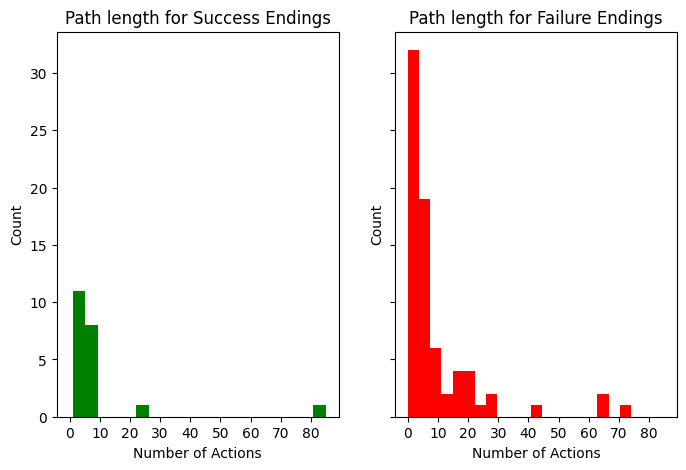

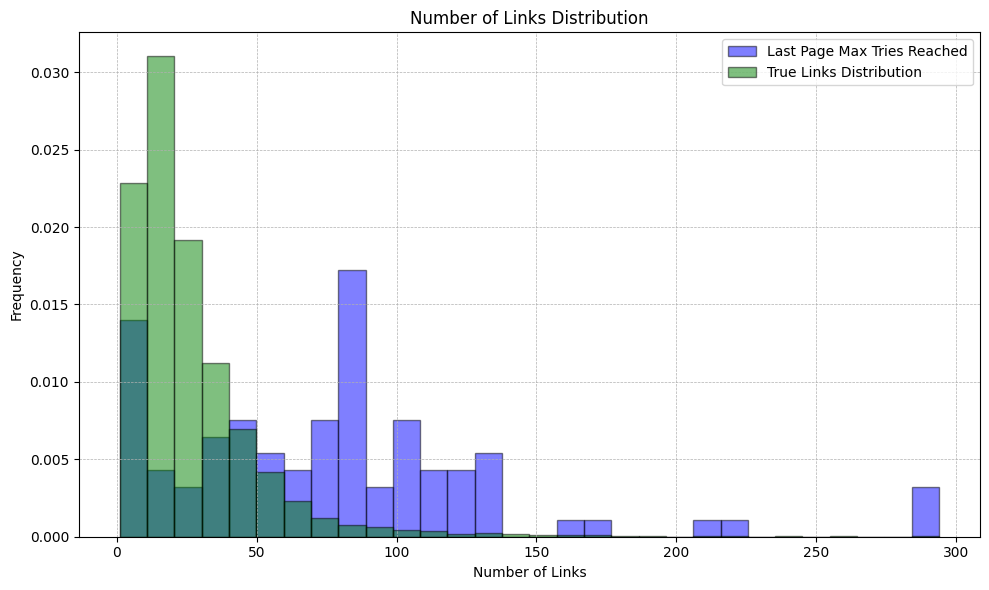

In [89]:
# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

runs_df = runs[0]['df'].query('spl>1')
runs_df['last_page'] = runs_df['visited_pages'].apply(lambda x: x.split(';')[-1])
runs_df['num_links_on_last_page'] = runs_df['last_page'].apply(lambda x: article_links_df.query('article==@x')['num_links'].values[0] if x in article_links_df['article'].values else 0)

print("Run configuration:")
print([(key, runs[0][key]) for key in runs[0].keys() if key != 'df'])
print("\n Total number of runs:", len(runs_df))
print("\nPercentage of successful runs:", round(len(runs_df.query('ending=="success"'))/len(runs_df)*100, 1))
print("\nPercentage of failed runs because of max_tries (too many errors)", round(len(runs_df.query('ending=="max_tries"'))/len(runs_df)*100, 1))
print("\nPercentage of failed runs because of max_actions (too many actions)", round(len(runs_df.query('ending=="max_actions"'))/len(runs_df)*100, 1))
print("\nTop 5 longest paths:\n", runs_df.sort_values(by='path_length', ascending=False).head(5)[['src', 'tgt', 'path_length']])
print("\nTop 5 pages that it gets stuck on the most with errors", runs_df.query("ending=='max_tries'")['last_page'].value_counts().head(5))

# Plotting histograms
fig, axs = plt.subplots(1, 2, figsize=(8, 5), sharey=True, sharex=True)
axs[0].set_xticks(range(0, max(runs_df['num_actions']), 10))
axs[1].set_xticks(range(0, max(runs_df['num_actions']), 10))
axs[0].hist(runs_df[runs_df['ending'] == 'success']['num_actions'], bins=20, color='green')
axs[0].set_title('Path length for Success Endings')
axs[0].set_xlabel('Number of Actions')
axs[0].set_ylabel('Count')

axs[1].hist(runs_df[runs_df['ending'] != 'success']['num_actions'], bins=20, color='red')
axs[1].set_title('Path length for Failure Endings')
axs[1].set_xlabel('Number of Actions')
axs[1].set_ylabel('Count')

plt.show()

plt.figure(figsize=(10, 6))

# Histogram for runs_df
plt.hist(runs_df['num_links_on_last_page'], bins=30, color='blue', edgecolor='black', alpha=0.5, label='Last Page Max Tries Reached', density=True)
plt.xlabel('Number of Links')
plt.ylabel('Frequency')
plt.title('Number of Links Distribution')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)

# Histogram for article_links_df
plt.hist(article_links_df['num_links'], bins=30, color='green', edgecolor='black', density=True, alpha=0.5, label='True Links Distribution')

# Add legend
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

Notes:
 - When there are a very low amount of links, the agent seems to make up stuff.
    - Example: last_page=Inductance, response_history = ... '{"next_page": "Electric_circuit"}', '{"next_page": "Galvani"}', '{"next_page": "Galvanism"}'
 - If the page has too many links, it just tries to click on the target: India (81 links), Iran (108 links) France (85 links), etc
    - Example: last_page=France, tgt=Marshall_Plan, response_history = ... '{"next_page": "Marshall_Plan"}', '{"next_page": "Marshall_Plan"}', '{"next_page": "Marshall_Plan"}'
    - Example: last_page=India, tgt=Bill_Gates, response_history = .. '{"next_page": "Bill Gates"}', '{"next_page": "Bill Gates"}', '{"next_page": "Bill Gates"}'
    - **curiously** it only got stuck on United_States 1 time, while the other big pages it got stuck 3 or 2

In [68]:
runs_df.query("ending=='max_tries' and last_page=='Iran'")[['src', 'tgt', 'last_page', 'num_links_on_last_page', 'ending', 'num_actions', 'path', 'response_history']]
#article_links_df.query("article=='Inductance'")

,src,tgt,last_page,num_links_on_last_page,ending,num_actions,path,response_history
27,Tooth_development,Train,Iran,108,max_tries,5,Tooth_development;Vitamin;Thiamine;Sulfur;Turkmenistan;Iran,"['{""next_page"": ""Vitamin""}', '{""next_page"": ""Thiamine""}', '{""next_page"": ""Sulfur""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}', '{""next_page"": ""Turkmenistan""}', '{""next_page"": ""Iran""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}', '{""next_page"": ""Train""}']"
66,Kosovo,Giant_Panda,Iran,108,max_tries,3,Kosovo;Islam;Qur'an;Iran,"['{""next_page"": ""Islam""}', '{""next_page"": ""Qur\'an""}', '{""next_page"": ""Iran""}', '{""next_page"": ""Giant Panda""}', '{""next_page"": ""Giant Panda""}', '{""next_page"": ""Giant Panda""}']"
89,William_N._Page,African_Grey_Parrot,Iran,108,max_tries,11,William_N._Page;Italy;Austria;Holy Roman Empire;Aachen;Paul of Tarsus;Athens;Parthenon;Persian_Empire;Islam;Mongol Empire;Iran,"['{""next_page"": ""Italy""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""Austria""}', '{""next_page"": ""Austria""}', '{""next_page"": ""Austrian_Czars""}', '{""next_page"": ""Holy Roman Empire""}', '{""next_page"": ""Aachen""}', '{""next_page"": ""Paul of Tarsus""}', '{""next_page"": ""Athens""}', '{""next_page"": ""Africa""}', '{""next_page"": ""Athens""}', '{""next_page"": ""Parthenon""}', '{""next_page"": ""Persian_Empire""}', '{""next_page"": ""Islam""}', '{""next_page"": ""Mongol Empire""}', '{""next_page"": ""Iran""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""African_Grey_Parrot""}', '{""next_page"": ""African_Grey_Parrot""}']"


In [36]:
runs_df['path'].apply(lambda x: x.split(';')[-1]).value_counts().head(10)

path
United States    3
India            3
France           3
Iran             3
Tanzania         3
Sulfur           2
Russia           2
Somalia          2
Gold             2
Islam            2
Name: count, dtype: int64

In [15]:
for run in runs:
    print(f"Config run_id={run['run_id']}, agent type={run['agent']}, fewshot={run['agent.fewshot']}")
    print(f"Number of completed games: {len(run['df'].query('reached_goal==True'))}")
    print()

runs[0]['df'].query("reached_goal == False")[['src', 'tgt', 'path', 'num_actions', 'response_history']]

Config run_id=0, agent type=link_click_dfs_agent, fewshot=5


UndefinedVariableError: name 'reached_goal' is not defined

In [26]:
# Add extra columns to the dfs

# get the llama2 tokenizer
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf")

# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

for run in runs:
    print(run['run_id'])
    run['df']['end_page'] = run['df'].apply(lambda x: x['path'].split(";")[-1], axis=1)
    # response history is a string of the form ['response1', 'response2', ...], we have to use parse
    run['df']['end_response'] = run['df'].apply(lambda x: ast.literal_eval(x['response_history'])[-1], axis=1)
    run['df']["end_user_prompt"]=run['df'].apply(lambda x: ast.literal_eval(x['user_prompt_history'])[-1], axis=1)
    run['df']["end_user_prompt_num_tokens"]=run['df'].apply(lambda x: len(tokenizer.tokenize(x['end_user_prompt'])), axis=1)
    run['df']['end_next_page'] = run['df'].apply(lambda x: parse.search("\"next_page\": \"{}\"", x['end_response'])[0], axis=1)
    run['df']['reached_goal'] = run['df'].apply(lambda x: x['end_page'] == x['tgt'], axis=1)
    run['df']['path_length'] = run['df'].apply(lambda x: len(x['path'].split(";")) - 1, axis=1)
    run['df']['end_response_extracted_json'] = run['df'].apply(lambda x: extract_json_from_response(x['end_response']), axis=1)
    run['df'] = pd.merge(run['df'], article_links_df, left_on='end_page', right_on='article', how='left')

    # rename num_links to end_page_num_links
    run['df'].rename(columns={'num_links': 'end_page_num_links'}, inplace=True)
    run['df'].rename(columns={'links': 'end_page_links'}, inplace=True)



0
1


TypeError: 'NoneType' object is not subscriptable

# Analyse agent run data

In [100]:
PATH_RUNS = "../../logs/inference/multiruns/multiturn_demo_comparison/2023-10-11_17-46-25"

system_demo_df = pd.read_csv(os.path.join(PATH_RUNS, "0/agent_runs.tsv"), sep="\t")
multiturn_demo_df = pd.read_csv(os.path.join(PATH_RUNS, "1/agent_runs.tsv"), sep="\t")

# get the llama2 tokenizer
tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-2-7b-chat-hf")

# get article links for some analysis
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)

# unite these two dfs, and add a column to indicate which system it is
system_demo_df['fewshot_mode'] = 'system_prompt'
multiturn_demo_df['fewshot_mode'] = 'multiturn'
runs_df = pd.concat([system_demo_df, multiturn_demo_df], ignore_index=True)

runs_df['end_page'] = runs_df.apply(lambda x: x['path'].split(";")[-1], axis=1)
# response history is a string of the form ['response1', 'response2', ...], we have to use parse
runs_df['end_response'] = runs_df.apply(lambda x: ast.literal_eval(x['response_history'])[-1], axis=1)
runs_df["end_user_prompt"]=runs_df.apply(lambda x: ast.literal_eval(x['user_prompt_history'])[-1], axis=1)
runs_df["end_user_prompt_num_tokens"]=runs_df.apply(lambda x: len(tokenizer.tokenize(x['end_user_prompt'])), axis=1)
runs_df['end_next_page'] = runs_df.apply(lambda x: parse.search("\"next_page\": \"{}\"", x['end_response'])[0], axis=1)
runs_df['reached_goal'] = runs_df.apply(lambda x: x['end_page'] == x['tgt'], axis=1)
runs_df['path_length'] = runs_df.apply(lambda x: len(x['path'].split(";")) - 1, axis=1)
runs_df['end_response_extracted_json'] = runs_df.apply(lambda x: extract_json_from_response(x['end_response']), axis=1)
runs_df = pd.merge(runs_df, article_links_df, left_on='end_page', right_on='article', how='left')

# rename num_links to end_page_num_links
runs_df.rename(columns={'num_links': 'end_page_num_links'}, inplace=True)
runs_df.rename(columns={'links': 'end_page_links'}, inplace=True)


In [72]:
runs_df.head()


,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,...,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,end_response_extracted_json,article,links,end_page_num_links
0,0,LinkClickAgent,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,3,8,2,"[""User: I'm currently on the page Albinism and...","['Assistant:\n{\n ""next_page"": ""Niger""\n}', '...",...,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}",User: I'm currently on the page United_States ...,1869,Tungsten,False,8,"{\n ""next_page"": ""Tungsten""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
1,1,LinkClickAgent,Heraclius,Gender,Heraclius;Muhammad;Islam;Sultan;Egypt;Sudan,3,5,2,"[""User: I'm currently on the page Heraclius an...","['Assistant:\n{\n ""next_page"": ""Muhammad""\n}'...",...,"Assistant:\n{\n ""next_page"": ""Gender""\n}",User: I'm currently on the page Sudan and the ...,747,Gender,False,5,"{\n ""next_page"": ""Gender""\n}",Sudan,Afghanistan;Africa;African_Union;Albania;Alger...,132.0
2,2,LinkClickAgent,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",3,7,2,"[""User: I'm currently on the page Salt_Lake_Ci...","['Assistant:\n{\n ""next_page"": ""Jazz""\n}', 'A...",...,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}",User: I'm currently on the page United_States ...,1873,Drum_and_bass,False,7,"{\n ""next_page"": ""Drum_and_bass""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
3,3,LinkClickAgent,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,3,4,2,"[""User: I'm currently on the page History_of_p...","['Assistant:\n{\n ""next_page"": ""Vladimir_Leni...",...,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}",User: I'm currently on the page United_States ...,1871,Oviraptor,False,4,"{\n ""next_page"": ""Oviraptor""\n}",United_States,Abraham_Lincoln;Advertising;Agriculture;Americ...,294.0
4,4,LinkClickAgent,Archbishop_of_Canterbury,Dead_Sea,Archbishop_of_Canterbury;Thomas_Cranmer;Willia...,3,5,2,"[""User: I'm currently on the page Archbishop_o...","['Assistant:\n{\n ""next_page"": ""Thomas_Cranme...",...,"Assistant:\n{\n ""next_page"": ""Dead_Sea""\n}",User: I'm currently on the page London and the...,666,Dead_Sea,False,5,"{\n ""next_page"": ""Dead_Sea""\n}",London,Alfred_the_Great;Ancient_Rome;Anglicanism;Arse...,102.0


In [77]:
runs_df['end_response_extracted_json'].value_counts()

end_response_extracted_json
{\n  "next_page": "Florida_East_Coast_Railway"\n}    2
{\n  "next_page": "Franklin_D._Roosevelt"\n}         2
{\n  "next_page": "Unix"\n}                          2
{\n  "next_page": "Mark_Twain_House"\n}              2
{\n  "next_page": "Magellanic_Penguin"\n}            2
{\n  "next_page": "Uzbekistan"\n}                    2
{\n  "next_page": "Oviraptor"\n}                     2
{\n  "next_page": "Drum_and_bass"\n}                 2
{\n  "next_page": "Indonesia"\n}                     2
{\n  "next_page": "Nazi_Germany"\n}                  1
{\n  "next_page": "Sega"\n}                          1
{\n  "next_page": "Tibet"\n\n}                       1
{\n  "next_page": "Ireland"\n\n}                     1
{\n  "next_page": "Dr._Seuss"\n}                     1
{\n  "next_page": "Law"\n\n}                         1
{\n  "next_page": "Malaria"\n}                       1
{\n  "next_page": "Tanzania"\n}                      1
{\n  "next_page": "Domestic_goat"\n} 

## Fewshot in system prompt

In [50]:
print("Number of failed runs because of too many actions: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and num_actions==15").count().iloc[0])
print("Number of failed runs because of too many invalid actions: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and num_errors==2").count().iloc[0])

Number of failed runs because of too many actions:  2
Number of failed runs because of too many invalid actions:  22


In [93]:
print("Number of unparseable json outputs: ", runs_df.query("fewshot_mode == 'system_prompt' and reached_goal == False and end_response_extracted_json.isna()").count().iloc[0])
print(runs_df.query("fewshot_mode == 'system_prompt' and end_response_extracted_json.isna()").end_response.tolist())

Number of unparseable json outputs:  0
[]


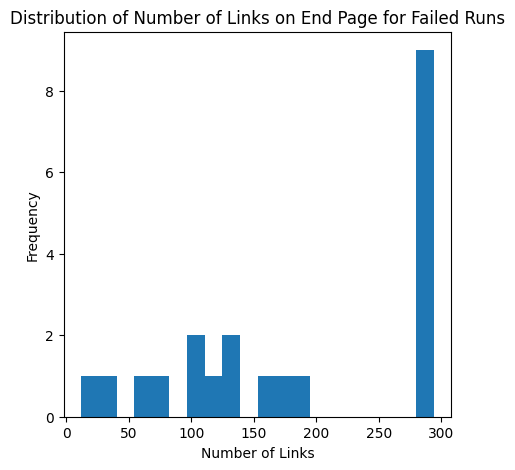

In [64]:
plt.figure(figsize=(5, 5))

runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2").end_page_num_links.hist(bins=20, grid=False)

plt.title('Distribution of Number of Links on End Page for Failed Runs')
plt.xlabel('Number of Links')
plt.ylabel('Frequency')

plt.show()


In [78]:
runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2 and end_page == 'United_States'")[['src', 'tgt', 'path', 'num_errors', 'end_page', 'end_response', 'end_response_extracted_json', 'end_next_page']]


,src,tgt,path,num_errors,end_page,end_response,end_response_extracted_json,end_next_page
0,Albinism,Tungsten,Albinism;Niger;United_States;Vietnam;Cambodia;...,2,United_States,"Assistant:\n{\n ""next_page"": ""Tungsten""\n}","{\n ""next_page"": ""Tungsten""\n}",Tungsten
2,"Salt_Lake_City,_Utah",Drum_and_bass,"Salt_Lake_City,_Utah;Jazz;Miles_Davis;Jazz;Mil...",2,United_States,"Assistant:\n{\n ""next_page"": ""Drum_and_bass""\n}","{\n ""next_page"": ""Drum_and_bass""\n}",Drum_and_bass
3,History_of_post-Soviet_Russia,Oviraptor,History_of_post-Soviet_Russia;Vladimir_Lenin;M...,2,United_States,"Assistant:\n{\n ""next_page"": ""Oviraptor""\n}","{\n ""next_page"": ""Oviraptor""\n}",Oviraptor
5,Taoism,Franklin_D._Roosevelt,Taoism;Buddhism;India;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Franklin_D._Roo...","{\n ""next_page"": ""Franklin_D._Roosevelt""\n}",Franklin_D._Roosevelt
7,Seawater,Tripoli,Seawater;Ocean;Northern_Mariana_Islands;United...,2,United_States,"Assistant:\n{\n ""next_page"": ""Bahamas""\n}","{\n ""next_page"": ""Bahamas""\n}",Bahamas
10,Romania,U2,Romania;Nadia_Comăneci;Pelé;David_Beckham;Mich...,2,United_States,"Assistant:\n{\n ""next_page"": ""Uzbekistan""\n}","{\n ""next_page"": ""Uzbekistan""\n}",Uzbekistan
13,Novel,Mark_Twain_House,Novel;James_Bond;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Mark_Twain_Hous...","{\n ""next_page"": ""Mark_Twain_House""\n}",Mark_Twain_House
16,Star_Trek__Deep_Space_Nine,Zinc,Star_Trek__Deep_Space_Nine;Soviet_Union;Moscow...,2,United_States,"Assistant:\n{\n ""next_page"": ""Zinc""\n}","{\n ""next_page"": ""Zinc""\n}",Zinc
18,Axe,Florida_East_Coast_Railway,Axe;France;United_States,2,United_States,"Assistant:\n{\n ""next_page"": ""Florida_East_Co...","{\n ""next_page"": ""Florida_East_Coast_Railway""\n}",Florida_East_Coast_Railway


In [12]:
# how many paths include United_States
runs_df["includes_us"] = runs_df.apply(lambda x: 'United_States' in x['path'].split(";"), axis=1)
runs_df.query("fewshot_mode == 'system_prompt' and includes_us == True").count()

agent_id                      11
agent_type                    11
src                           11
tgt                           11
path                          11
fewshot                       11
num_actions                   11
num_errors                    11
user_prompt_history           11
response_history              11
fewshot_mode                  11
end_page                      11
end_response                  11
end_user_prompt               11
end_user_prompt_num_tokens    11
end_next_page                 11
reached_goal                  11
path_length                   11
includes_us                   11
dtype: int64

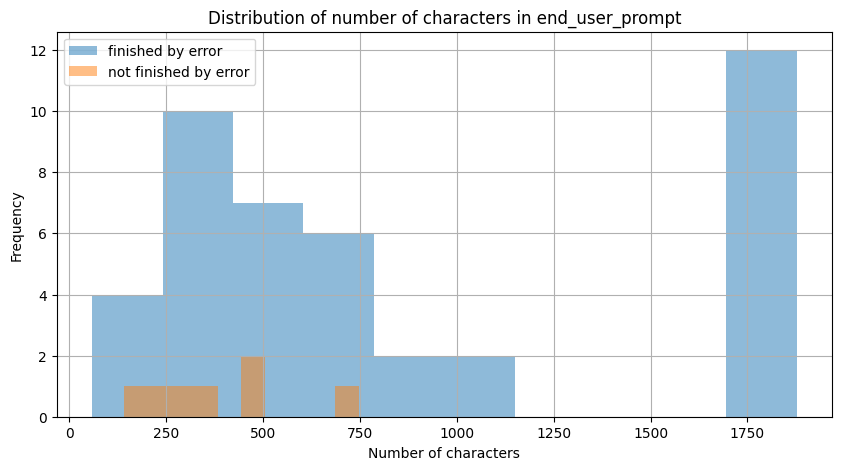

In [13]:
# runs_df.query("fewshot_mode == 'system_prompt' and num_errors == 2").end_user_prompt.tolist()
# runs_df.end_user_prompt.str.len().hist()
# plt.xlabel('Number of characters')
# plt.ylabel('Frequency')
# plt.title('Distribution of number of characters in end_user_prompt')

plt.figure(figsize=(10, 5))

runs_df[runs_df['num_errors'] == 2].end_user_prompt_num_tokens.hist(alpha=0.5, label='finished by error')
runs_df[runs_df['num_errors'] != 2].end_user_prompt_num_tokens.hist(alpha=0.5, label='not finished by error')

plt.xlabel('Number of characters')
plt.ylabel('Frequency')
plt.title('Distribution of number of characters in end_user_prompt')
plt.legend()

plt.show()


## Fewshot multi-turn

In [24]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == True")

,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,fewshot_mode,end_page,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,includes_us
31,6,LinkClickAgent,Milk,Domestic_goat,Milk;Domestic_goat,3,1,0,"[""I'm currently on the page Milk and the targe...","['{\n ""next_page"": ""Domestic_goat""\n}']",multiturn,Domestic_goat,"{\n ""next_page"": ""Domestic_goat""\n}",I'm currently on the page Milk and the target ...,285,Domestic_goat,True,1,False
38,13,LinkClickAgent,Novel,Mark_Twain_House,Novel;Miguel_de_Cervantes;William_Shakespeare;...,3,8,0,"[""I'm currently on the page Novel and the targ...","['{\n ""next_page"": ""Miguel_de_Cervantes""\n}',...",multiturn,Mark_Twain_House,"{\n ""next_page"": ""Mark_Twain_House""\n}",I'm currently on the page Mark_Twain and the t...,141,Mark_Twain_House,True,8,False
47,22,LinkClickAgent,Nile,Indonesia,Nile;Egypt;Islam;Indonesia,3,3,0,"[""I'm currently on the page Nile and the targe...","['{\n ""next_page"": ""Egypt""\n\n}', '{\n ""next...",multiturn,Indonesia,"{\n ""next_page"": ""Indonesia""\n}",I'm currently on the page Islam and the target...,458,Indonesia,True,3,False


In [28]:
print("Number of failed runs because of too many actions: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_actions==15").count().iloc[0])
print("Number of failed runs because of too many invalid actions: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_errors==2").count().iloc[0])

Number of failed runs because of too many actions:  1
Number of failed runs because of too many invalid actions:  21


In [99]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and num_errors==0").path.tolist()

['Giant_Panda;DNA;Thomas_Jefferson;Washington, D.C.;Economics;Market;Money;Coin;India;Ramayana;Sanskrit;Vowel;French_language;Vietnam;China;Tibet']

In [30]:
runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False").end_page.value_counts()

end_page
United_States              3
Phosphorus                 1
Great_comet                1
Vietnam                    1
Sound                      1
Los_Angeles,_California    1
Bristol                    1
Moscow                     1
Human                      1
Russia                     1
Tibet                      1
Rhine                      1
Ukraine                    1
Germany                    1
Physics                    1
Volcano                    1
Jerusalem                  1
France                     1
United_Kingdom             1
Time_zone                  1
Name: count, dtype: int64

In [94]:
print("Number of unparseable json outputs: ", runs_df.query("fewshot_mode == 'multiturn' and reached_goal == False and end_response_extracted_json.isna()").count().iloc[0])
print(runs_df.query("fewshot_mode == 'multiturn' and end_response_extracted_json.isna()").end_response.tolist())
runs_df.query("fewshot_mode == 'multiturn' and end_response_extracted_json.isna()")[['src', 'tgt', 'path', 'end_page', 'end_response', 'end_next_page', 'end_response_extracted_json']]

Number of unparseable json outputs:  4
['{\n  "next_page": "Sexism"', '{\n  "next_page": "Metallurgy"\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\necause zinc is a metal, you should click on the "Metallurgy" link to get closer to the target page.', '{\n  "next_page": "Sports"\n\nFrom there, you can click on "Football (soccer)" to get to the page "Boston RFC".', '{\n  "next_page": "Tobacco"']


,src,tgt,path,end_page,end_response,end_next_page,end_response_extracted_json
26,Heraclius,Gender,Heraclius;Muhammad;Women's_rights;Suffrage;Fra...,Rhine,"{\n ""next_page"": ""Sexism""",Sexism,None
41,Star_Trek__Deep_Space_Nine,Zinc,Star_Trek__Deep_Space_Nine;Soviet_Union;Moscow,Moscow,"{\n ""next_page"": ""Metallurgy""\n\n\n\n\n\n\n\n...",Metallurgy,None
42,British_Isles,Boston_RFC,British_Isles;River_Severn;Wales;Rugby_World_C...,Bristol,"{\n ""next_page"": ""Sports""\n\nFrom there, you ...",Sports,None
48,Llywelyn_the_Great,Kuru_(disease),Llywelyn_the_Great;Tower_of_London;H5N1;Vietnam,Vietnam,"{\n ""next_page"": ""Tobacco""",Tobacco,None


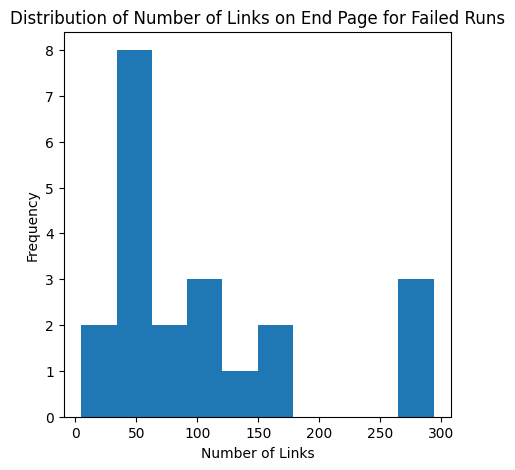

In [67]:
plt.figure(figsize=(5, 5))

runs_df.query("fewshot_mode == 'multiturn' and num_errors == 2").end_page_num_links.hist(grid=False)

plt.title('Distribution of Number of Links on End Page for Failed Runs')
plt.xlabel('Number of Links')
plt.ylabel('Frequency')

plt.show()

In [112]:
# Cases where the tgt page was in the end_page_links but the agent didn't reach it
runs_df.query("not end_page_links.isna()")[runs_df.query("not end_page_links.isna()").apply(lambda x: x['tgt'] in x['end_page_links'].split(";"), axis=1).values]

,agent_id,agent_type,src,tgt,path,fewshot,num_actions,num_errors,user_prompt_history,response_history,...,end_response,end_user_prompt,end_user_prompt_num_tokens,end_next_page,reached_goal,path_length,end_response_extracted_json,article,end_page_links,end_page_num_links
29,4,LinkClickAgent,Archbishop_of_Canterbury,Dead_Sea,Archbishop_of_Canterbury;Rome;Jerusalem,3,2,2,"[""I'm currently on the page Archbishop_of_Cant...","['{\n ""next_page"": ""Rome""\n}', '{\n ""next_pa...",...,"{\n ""next_page"": ""Dead_Sea Scrolls""\n\n}",I'm currently on the page Jerusalem and the ta...,276,Dead_Sea Scrolls,False,2,"{\n ""next_page"": ""Dead_Sea Scrolls""\n\n}",Jerusalem,Albert_Einstein;Ancient_Egypt;Arab-Israeli_con...,40.0
31,6,LinkClickAgent,Milk,Domestic_goat,Milk;Domestic_goat,3,1,0,"[""I'm currently on the page Milk and the targe...","['{\n ""next_page"": ""Domestic_goat""\n}']",...,"{\n ""next_page"": ""Domestic_goat""\n}",I'm currently on the page Milk and the target ...,285,Domestic_goat,True,1,"{\n ""next_page"": ""Domestic_goat""\n}",Domestic_goat,Animal;Bangladesh;Belize;Bible;Brain;Brazil;Bu...,34.0


# Explore Wikispeedia data

In [33]:
article_links_df = pd.read_csv(os.path.join(PATH_IN, "article_links.tsv"), sep="\t")
article_links_df['num_links'] = article_links_df.apply(lambda x: len(x['links'].split(";")), axis=1)
article_links_df.head()

,article,links,num_links
0,Áedán_mac_Gabráin,Bede;Columba;Dál_Riata;Great_Britain;Ireland;I...,11
1,Åland,20th_century;Baltic_Sea;Crimean_War;Currency;E...,19
2,Édouard_Manet,Absinthe;Beer;Claude_Monet;Diego_Velázquez;Edg...,20
3,Éire,Canada;English_language;George_VI_of_the_Unite...,8
4,Óengus_I_of_the_Picts,Dál_Riata;Durham;England;Great_Britain;Ireland...,10


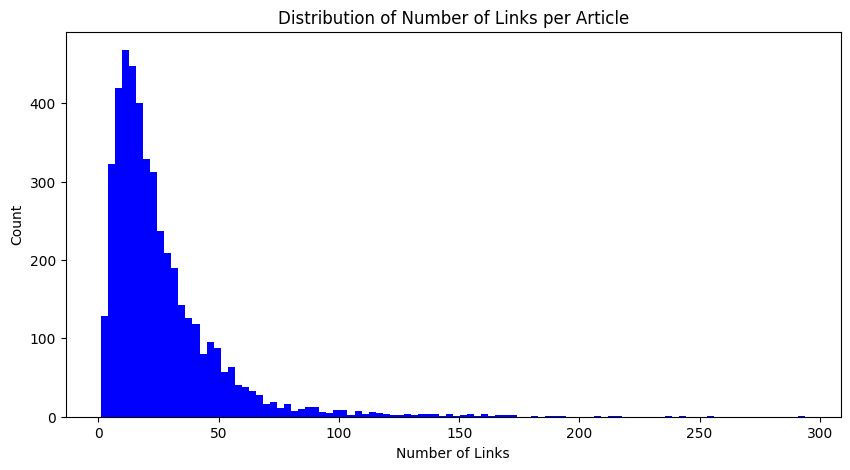

Quantiles of number of links: 0.25    11.0
0.50    19.0
0.75    33.0
0.90    51.0
0.95    67.0
Name: num_links, dtype: float64


In [117]:

plt.figure(figsize=(10, 5))
plt.hist(article_links_df['num_links'], bins=100, color='blue')#, log=True)
plt.xlabel('Number of Links')
plt.ylabel('Count')
plt.title('Distribution of Number of Links per Article')
plt.show()

print(f"Quantiles of number of links: {article_links_df['num_links'].quantile([0.25, 0.5, 0.75, 0.9, 0.95])}")

In [116]:
# average number of links per article
article_links_df['num_links'].mean()

26.13516459559625

In [47]:
# top 10 pages with most links
from pprint import pprint
pprint([(row['article'], row['num_links']) for _, row in article_links_df.sort_values(by='num_links', ascending=False).head(10).iterrows()])


[('United_States', 294),
 ('Driving_on_the_left_or_right', 255),
 ('List_of_countries', 244),
 ('List_of_circulating_currencies', 236),
 ('List_of_sovereign_states', 216),
 ('Africa', 212),
 ('List_of_countries_by_system_of_government', 207),
 ('Lebanon', 192),
 ('Interpol', 191),
 ('Armenia', 186)]


# Build paths_real_processed_df
`paths_real_df` (from Akhil) has the columns:
 - hashed_ip: user identifier
 - timestamp: time of the game
 - src, tgt: source and target pages
 - is_path_finished: whether the user reached the target page
 - failure_type: reason for failure (restart, timout, ...)
 - path: path taken (including backtracks)
 - hpl: Human Path Length (number of clicks by human, including backtracks)
 - spl: Shortest Path Length (shortest possible path length for that pair)
 - duration_in_sec: time taken by user
 - target_in_degree: number of incoming links to target page
 - user_path_rating: 1-5 rating of path difficulty by user

We're gonna add:
 - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
 - effective_path: path taken by user excluding backtracks
 - shortest_effective_path: shortest effective path made by human, for that pair
 - hepl: Human Effective Path Length (effective path length for that game instance)
 - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

The final df is `paths_real_processed_df`

In [115]:
# `paths_real_df` (from Akhil) has the columns:
#  - hashed_ip: user identifier
#  - timestamp: time of the game
#  - src, tgt: source and target pages
#  - is_path_finished: whether the user reached the target page
#  - failure_type: reason for failure (restart, timout, ...)
#  - path: path taken (including backtracks)
#  - hpl: Human Path Length (number of clicks by human, including backtracks)
#  - spl: Shortest Path Length (shortest possible path length for that pair)
#  - duration_in_sec: time taken by user
#  - target_in_degree: number of incoming links to target page
#  - user_path_rating: 1-5 rating of path difficulty by user

# We're gonna add:
#  - shpl: Shortest Human Path Length (lowest number of clicks by human, for that pair)
#  - effective_path: path taken by user excluding backtracks
#  - shortest_effective_path: shortest effective path made by human, for that pair
#  - hepl: Human Effective Path Length (effective path length for that game instance)
#  - shepl: Shortest Human Effective Path Length (shortest effective path length made by human, for that pair)

# The final df is `paths_real_processed_df`

paths_real_processed_df = pd.read_csv(PATH_IN + 'paths_real_df.csv')

paths_real_processed_df["effective_path"] = paths_real_processed_df.apply(lambda row: effective_path(row["path"]), axis=1)
paths_real_processed_df["hepl"] = paths_real_processed_df.apply(lambda row: len(row["effective_path"].split(";"))-1, axis=1)

# add a column that is the shortest human path length for that pair, by choosing the minimum path_length for all games with that pair
shpl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hpl": "min"}).reset_index().rename(columns={"hpl": "shpl"})
shepl = paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "min"}).reset_index().rename(columns={"hepl": "shepl"})
# the shortest effective path is the path with the minimum hepl for that pair
paths_real_processed_df[paths_real_processed_df["is_path_finished"] == 1].groupby(["src", "tgt"]).agg({"hepl": "min"}).reset_index().rename(columns={"effective_path": "shortest_effective_path"})

# paths_real_processed_df = pd.merge(paths_real_processed_df, shpl, on=['src', 'tgt'], how='left')
# paths_real_processed_df = pd.merge(paths_real_processed_df, shepl, on=['src', 'tgt'], how='left')
# paths_real_processed_df = pd.merge(paths_real_processed_df, shortest_effective_path, on=['src', 'tgt'], how='left')

# paths_real_processed_df

,src,tgt,hepl
0,10th_century,11th_century,1
1,10th_century,Banknote,4
2,10th_century,Country,2
3,10th_century,Harlem_Globetrotters,3
4,10th_century,History_of_democracy,5
...,...,...,...
28713,Zulu,Language,2
28714,Zulu,Slovenia,3
28715,Zürich,Billie_Holiday,4
28716,Zürich,Mediterranean_Sea,3


In [ ]:
paths_real_processed_df.to_csv(PATH_IN + 'paths_real_processed.tsv', sep='\t', index=False)